## 0. Imports & Setup

In [1]:
import gc
import os
import shutil
import random
from datetime import datetime

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr


In [2]:
def set_seed(seed):
    """
    Use this to set ALL the random seeds to a fixed value and take out any randomness from cuda kernels
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False  # uses the inbuilt cudnn auto-tuner to find the fastest convolution algorithms
    torch.backends.cudnn.enabled   = False

    return True

In [3]:
# Detect HPC vs local
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Use HPC path if it exists, otherwise local
IS_HPC = os.path.exists(HPC_ROOT)
ROOT = HPC_ROOT if IS_HPC else REPO_ROOT

# Flags
SAVE_PREDICTIONS = True  # Save predictions in zarr?
USE_SATELLITE = True     # Use satellite inference?

# Period start and end
START_DATE = "1993-01-01"
END_DATE = "2024-12-01"

# Ensemble member config
MEMBER_ID = 0
# int(os.environ.get("PBS_ARRAY_INDEX", "0"))  # default to 0

# print("PBS_ARRAY_INDEX:", os.environ.get("PBS_ARRAY_INDEX", "not-set"))

# Use deterministic but different seeds for members 0–9.
BASE_SEED = 42
SEED = BASE_SEED + MEMBER_ID

assert 0 <= MEMBER_ID <= 9
assert SEED == BASE_SEED + MEMBER_ID
set_seed(SEED)

print("Ensemble member:", MEMBER_ID)
print("Seed:", SEED)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
print(f"Run timestamp: {RUN_TIMESTAMP}")

# Derived paths
DATA_ROOT             = os.path.join(ROOT, "data")
PROCESSED_DATA_DIR    = os.path.join(DATA_ROOT, "processed")
CMIP6_LOAD_DIR        = os.path.join(PROCESSED_DATA_DIR, "cmip6")
INPUT4MIPS_LOAD_DIR   = os.path.join(PROCESSED_DATA_DIR, "input4mips")
SAT_LOAD_DIR          = os.path.join(PROCESSED_DATA_DIR, "satellite")
XGBOOST_CLIM_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "xgboost_thermal")
PRED_SAVE_DIR         = os.path.join(DATA_ROOT, "predictions", "prior", "ensemble_members")
FIGURES_DIR           = os.path.join(ROOT, "figures")
CHECKPOINT_DIR        = os.path.join(ROOT, "checkpoints")

# create write dirs if don't exist
for dir_paths in [PRED_SAVE_DIR, FIGURES_DIR, CHECKPOINT_DIR]:
    if not os.path.exists(dir_paths):
        os.makedirs(dir_paths, exist_ok=True)

best_model_path = os.path.join(CHECKPOINT_DIR, "resnet_best_member{MEMBER_ID}_seed{SEED}.pt")
last_model_path = os.path.join(CHECKPOINT_DIR, "resnet_last_member{MEMBER_ID}_seed{SEED}.pt")

# choose one:
# "train"  -> always train from scratch - builds train, val, test
# "resume" -> resume from last checkpoint if it exists, ow train from scratch - buils train, val, test
# "eval"   -> skip training and load best checkpoint only - builds test only
RUN_MODE = "train"

print(f"Running on: {'HPC' if IS_HPC else 'local'}")
print(f"Root:                  {ROOT}")
print(f"Data root:             {DATA_ROOT}")
print(f"CMIP6:                 {CMIP6_LOAD_DIR}")
print(f"Input4MIPS:            {INPUT4MIPS_LOAD_DIR}")
print(f"XGBoost Climatology:   {XGBOOST_CLIM_LOAD_DIR}")
print(f"Predictions save:      {PRED_SAVE_DIR}")
print(f"Figures:               {FIGURES_DIR}")
print(f"Checkpoints:           {CHECKPOINT_DIR}")

print(f"\nRUN_MODE = {RUN_MODE}")
print("Best checkpoint:", best_model_path)
print("Last checkpoint:", last_model_path)

Ensemble member: 0
Seed: 42
Using device: cuda
Run timestamp: 20260823_202456
Running on: HPC
Root:                  /rds/general/user/efs25/home/irp-efs25
Data root:             /rds/general/user/efs25/home/irp-efs25/data
CMIP6:                 /rds/general/user/efs25/home/irp-efs25/data/processed/cmip6
Input4MIPS:            /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips
XGBoost Climatology:   /rds/general/user/efs25/home/irp-efs25/data/processed/xgboost_thermal
Predictions save:      /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members
Figures:               /rds/general/user/efs25/home/irp-efs25/figures
Checkpoints:           /rds/general/user/efs25/home/irp-efs25/checkpoints

RUN_MODE = train
Best checkpoint: /rds/general/user/efs25/home/irp-efs25/checkpoints/resnet_best_member{MEMBER_ID}_seed{SEED}.pt
Last checkpoint: /rds/general/user/efs25/home/irp-efs25/checkpoints/resnet_last_member{MEMBER_ID}_seed{SEED}.pt


### Load CMIP6 and Input4MIPS Zarrs

In [4]:
# if HPC load all cmip models and input4mips atm co2
# if local, load only cesm2 and atm co2
# + satellite if USE_SATELLITE

ALL_MODELS = ["CESM2", "CanESM5", "CanESM5-CanOE", "GFDL-ESM4", "UKESM1-0-LL"]
TEST_MODEL = "UKESM1-0-LL"

if RUN_MODE == "eval":
    MODELS_TO_LOAD = [TEST_MODEL]
else:
    MODELS_TO_LOAD = ALL_MODELS if IS_HPC else ["CESM2", TEST_MODEL]

datasets = {}
for model_name in MODELS_TO_LOAD:
    model_path = os.path.join(CMIP6_LOAD_DIR, f"{model_name}.zarr")
    if os.path.exists(model_path):
        datasets[model_name] = xr.open_zarr(model_path)
        print(f"Loaded {model_name}")
    else:
        print(f"{model_name} not found at {model_path} - skipping")

# load atmospheric CO2
CO2_PATH = os.path.join(INPUT4MIPS_LOAD_DIR, "atmCO2_1850_2100_regridded.zarr")
assert os.path.exists(CO2_PATH), f"Atmospheric CO2 file not found: {CO2_PATH}"

ds_co2 = xr.open_zarr(CO2_PATH)
print("\nLoaded atmospheric CO2:", CO2_PATH)
print(f"Variables: {list(ds_co2.data_vars)}")

Loaded CESM2
Loaded CanESM5
Loaded CanESM5-CanOE
Loaded GFDL-ESM4


Loaded UKESM1-0-LL

Loaded atmospheric CO2: /rds/general/user/efs25/home/irp-efs25/data/processed/input4mips/atmCO2_1850_2100_regridded.zarr
Variables: ['mole_fraction_of_carbon_dioxide_in_air']


### Load satellite and NOAA xCO2 Zarrs

In [5]:
if USE_SATELLITE:
    SATELLITE_PATH = os.path.join(SAT_LOAD_DIR, "satellite_covariates_1deg_1970_2024.zarr")
    assert os.path.exists(SATELLITE_PATH), f"Satellite covariate file not found: {SATELLITE_PATH}"

    ds_sat = xr.open_zarr(SATELLITE_PATH).sel(time=slice(START_DATE, END_DATE))

    print("\nLoaded satellite:", SATELLITE_PATH)
    print("Variables", list(ds_sat.data_vars))
    print("Time coverage:", str(ds_sat.time.values[0])[:10], "to", str(ds_sat.time.values[-1])[:10])

    # Load NOAA atmospheric CO2
    NOAA_XCO2_PATH = os.path.join(SAT_LOAD_DIR, "noaa_gml_mbl_1x1_monthly.zarr")
    assert os.path.exists(NOAA_XCO2_PATH), f"NOAA CoO2 covariate file not found: {NOAA_XCO2_PATH}"

    ds_xco2 = xr.open_zarr(NOAA_XCO2_PATH, consolidated=True)

    print("\nLoaded NOAA xCO2:", NOAA_XCO2_PATH)
    print("Variables:", ds_xco2["atm_co2_xco2"].attrs)
    print("Time coverage:", ds_xco2["time"].values[[0, -1]])

    # Load xgboost climatology
    XGBOOST_CLIM_PATH = os.path.join(XGBOOST_CLIM_LOAD_DIR, "pco2_thermal_xgboost_1993_2024_1deg_monthly.zarr")
    assert os.path.exists(XGBOOST_CLIM_PATH), f"XGBoost climatology file not found: {XGBOOST_CLIM_PATH}"

    ds_xgb_clim = xr.open_zarr(XGBOOST_CLIM_PATH, consolidated=True)

    pco2_thermal_full = (
        ds_xgb_clim["pco2_thermal"]
        .transpose("time", "lat", "lon")
        .astype(np.float32)
    )

    assert ds_xgb_clim["pco2_thermal"].attrs.get("units") == "uatm"
    assert pco2_thermal_full.sizes["time"] == len(ds_sat.time)
    assert np.array_equal(pco2_thermal_full.time.values, ds_sat.time.values)
    assert np.array_equal(pco2_thermal_full.lat.values, ds_sat.lat.values)
    assert np.array_equal(pco2_thermal_full.lon.values, ds_sat.lon.values)

    print("Thermal component aligned:", pco2_thermal_full.shape)

    print(f"Loaded XGBoost pCO2 climatology: {XGBOOST_CLIM_PATH}")
    print(f"Variables: {list(ds_xgb_clim.data_vars)}")
    print(f"Dims: {dict(ds_xgb_clim.sizes)}")


Loaded satellite: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
Variables ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'sos', 'sos_anom', 'tos', 'tos_anom']
Time coverage: 1993-01-01 to 2024-12-01

Loaded NOAA xCO2: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/noaa_gml_mbl_1x1_monthly.zarr
Variables: {'citation': 'Lan, X., Tans, P., Thoning, K., & NOAA Global Monitoring Laboratory. (2024). NOAA Greenhouse Gas Marine Boundary Layer Reference - CO2. [Data set]. NOAA GML. https://doi.org/10.15138/DVNP-F961', 'long_name': 'Monthly atmospheric CO2 mole fraction from NOAA GML MBL reference, broadcast uniformly', 'reference_scale': 'X2019', 'source': 'NOAA GML Marine Boundary Layer Reference (zonal, global-mean)', 'spatial_representation': 'Global scalar reference broadcast across a 1x1 degree grid; not spatially resolved', 'standard_name': 'mole_fraction_of_carbon_dioxide_in_air', 'temporal_resolution': 'month

### Load from checkpoint if in eval mode

In [6]:
def ensure_history_dict(history_obj):
    if not isinstance(history_obj, dict):
        return {"train_loss": [], "val_loss": []}

    train_hist = [float(x) for x in history_obj.get("train_loss", [])]
    val_hist = [float(x) for x in history_obj.get("val_loss", [])]
    return {"train_loss": train_hist, "val_loss": val_hist}


def load_checkpoint_with_history(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    hist = ensure_history_dict(checkpoint.get("history", {}))

    if len(hist["train_loss"]) == 0 and "train_loss" in checkpoint:
        hist["train_loss"] = [float(checkpoint["train_loss"])]
    if len(hist["val_loss"]) == 0 and "val_loss" in checkpoint:
        hist["val_loss"] = [float(checkpoint["val_loss"])]

    checkpoint["history"] = hist
    return checkpoint


def load_norm_stats_from_checkpoint(checkpoint):
    required = ["input_means", "input_stds", "target_means", "target_stds"]
    missing = [k for k in required if k not in checkpoint]
    if missing:
        raise KeyError(
            f"Checkpoint missing normalisation stats: {missing}. "
            "Re-save the checkpoint with input/target means/stds included."
        )

    input_means = np.asarray(checkpoint["input_means"], dtype=np.float32)
    input_stds = np.asarray(checkpoint["input_stds"], dtype=np.float32)
    target_means = np.asarray(checkpoint["target_means"], dtype=np.float32)
    target_stds = np.asarray(checkpoint["target_stds"], dtype=np.float32)
    return input_means, input_stds, target_means, target_stds


history = {"train_loss": [], "val_loss": []}
start_epoch = 0
best_val_loss = np.inf
checkpoint = None

if RUN_MODE == "eval":
    assert os.path.exists(best_model_path), f"No best checkpoint found at {best_model_path}"
    checkpoint = load_checkpoint_with_history(best_model_path)
    input_means, input_stds, target_means, target_stds = load_norm_stats_from_checkpoint(checkpoint)
    history = checkpoint["history"]
    start_epoch = checkpoint.get("epoch", 0)
    best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("val_loss", np.inf))
    DO_TRAIN = False

elif RUN_MODE == "resume":
    assert os.path.exists(last_model_path), f"No last checkpoint found at {last_model_path}"
    
    checkpoint = load_checkpoint_with_history(last_model_path)
    
    input_means, input_stds, target_means, target_stds = load_norm_stats_from_checkpoint(checkpoint)
    history = checkpoint["history"]
    start_epoch = checkpoint.get("epoch", 0)
    best_val_loss = checkpoint.get("best_val_loss", checkpoint.get("val_loss", np.inf))
    
    DO_TRAIN = True
    
    print(f"Resuming member {MEMBER_ID} from epoch {start_epoch}"    )
elif RUN_MODE == "train":
    DO_TRAIN = True

else:
    raise ValueError(f"Unknown RUN_MODE: {RUN_MODE}")

## 1. Preprocessing

##### Log transform chl and mld
Apply the same to all CMIP6 models, held out UKESM model and satellite covariate stacks

In [7]:
CHL_FLOOR = 1e-6   # mg m^-3
MLD_FLOOR = 1e-3   # m

def add_log_covariates(ds, chl_floor=CHL_FLOOR, mld_floor=MLD_FLOOR):
    """ 
    Add log10 Chl-a/MLD fields and anomalies calculated in log space.
    Existing raw variables and raw anomalies remain unchanged.
    """
    chlos_log = np.log10(ds["chlos"].clip(min=chl_floor)).rename("chlos_log")

    mlotst_log = np.log10(ds["mlotst"].clip(min=mld_floor)).rename("mlotst_log")

    chlos_log_anom = (
        chlos_log.groupby("time.month")
        - chlos_log.groupby("time.month").mean("time")
    ).rename("chlos_log_anom")

    mlotst_log_anom = (
        mlotst_log.groupby("time.month")
        - mlotst_log.groupby("time.month").mean("time")
    ).rename("mlotst_log_anom")

    ds = ds.assign(
        chlos_log=chlos_log.astype(np.float32),
        chlos_log_anom=chlos_log_anom.astype(np.float32),
        mlotst_log=mlotst_log.astype(np.float32),
        mlotst_log_anom=mlotst_log_anom.astype(np.float32),
    )

    return ds


# Apply to all loaded CMIP6 datasets
for model_name in list(datasets):
    print(f"Adding log covariates: {model_name}", flush=True)

    datasets[model_name] = add_log_covariates(datasets[model_name])

    print("  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom", flush=True)

# Apply to satellite
if USE_SATELLITE:
    print("Adding log covariates: satellite stack", flush=True)

    ds_sat = add_log_covariates(ds_sat)

    print("  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom", flush=True)

Adding log covariates: CESM2


  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom


Adding log covariates: CanESM5


  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom


Adding log covariates: CanESM5-CanOE


...

  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom


Adding log covariates: UKESM1-0-LL


  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom


Adding log covariates: satellite stack


  Added: chlos_log, chlos_log_anom, mlotst_log, mlotst_log_anom


In [8]:
required_log_vars = [
    "chlos_log",
    "chlos_log_anom",
    "mlotst_log",
    "mlotst_log_anom",
]

for model_name, ds_model in datasets.items():
    missing = [
        var for var in required_log_vars
        if var not in ds_model.data_vars
    ]

    assert not missing, f"{model_name} missing log variables: {missing}"

print("All CMIP6 datasets contain log covariates")

if USE_SATELLITE:
    missing_sat = [
        var for var in required_log_vars
        if var not in ds_sat.data_vars
    ]

    assert not missing_sat, f"Satellite missing log variables: {missing_sat}"

    print("Satellite stack contains log covariates")

All CMIP6 datasets contain log covariates
Satellite stack contains log covariates


### Train/val/test splits

Train/test split by CMIP6 model (leave on out)

Chronological train/validation split within training models

In [9]:
TRAIN_YEAR_BLOCKS = [(1850, 1992), (2025, 2100)]
VAL_YEAR_BLOCKS = [(1993, 2024)]
TEST_RECON_BLOCKS = [(1993, 2024)]
TEST_FULL_BLOCKS = [(1850, 2100)]

def subset_year_blocks(ds, year_blocks):
    years = np.array([t.year for t in ds.time.values])
    mask = np.zeros(ds.sizes["time"], dtype=bool)
    for start, end in year_blocks:
        mask |= (years >= start) & (years <= end)
    return ds.isel(time=mask)


def describe_split(name, ds):
        years = np.array([t.year for t in ds.time.values])
        print(f"{name}: {ds.sizes['time']} months | {years.min()}-{years.max()} | {len(np.unique(years))} years")
    
    
TRAIN_MODELS = [m for m in ALL_MODELS if m != TEST_MODEL and m in datasets]

assert TEST_MODEL in datasets, f"{TEST_MODEL} not loaded, cannot hold it out for testing."

print(f"Train models ({len(TRAIN_MODELS)}): {TRAIN_MODELS}")
print(f"Test model: {TEST_MODEL}")

test_dataset = datasets[TEST_MODEL]

test_dataset_full = subset_year_blocks(test_dataset, TEST_FULL_BLOCKS)
test_dataset_recon = subset_year_blocks(test_dataset, TEST_RECON_BLOCKS)

if RUN_MODE != "eval":
    train_split_datasets = {
        m: subset_year_blocks(datasets[m], TRAIN_YEAR_BLOCKS)
        for m in TRAIN_MODELS
    }

    val_split_datasets = {
        m: subset_year_blocks(datasets[m], VAL_YEAR_BLOCKS)
        for m in TRAIN_MODELS
    }
else:
    valsplitdatasets = {}

lats = test_dataset_recon.lat.values
lons = test_dataset_recon.lon.values

if RUN_MODE != "eval":
    for model_name in TRAIN_MODELS:
        describe_split(f"{model_name} train", train_split_datasets[model_name])
        describe_split(f"{model_name} val", val_split_datasets[model_name])

# for all modes
describe_split(f"{TEST_MODEL} test (reconstruction)", test_dataset_recon)
describe_split(f"{TEST_MODEL} test (full)", test_dataset_full)

Train models (4): ['CESM2', 'CanESM5', 'CanESM5-CanOE', 'GFDL-ESM4']
Test model: UKESM1-0-LL


CESM2 train: 2628 months | 1850-2100 | 219 years
CESM2 val: 384 months | 1993-2024 | 32 years
CanESM5 train: 2628 months | 1850-2100 | 219 years
CanESM5 val: 384 months | 1993-2024 | 32 years
CanESM5-CanOE train: 2628 months | 1850-2100 | 219 years
CanESM5-CanOE val: 384 months | 1993-2024 | 32 years
GFDL-ESM4 train: 2628 months | 1850-2100 | 219 years
GFDL-ESM4 val: 384 months | 1993-2024 | 32 years
UKESM1-0-LL test (reconstruction): 384 months | 1993-2024 | 32 years
UKESM1-0-LL test (full): 3012 months | 1850-2100 | 251 years


### Build Stacks

##### Add cyclical month encoded channels

In [10]:
def extract_months(time_values):
    # to work for both cmip and satellite - either cftime or np.datetime64
    first = time_values[0]
    if hasattr(first, "month"): # cftime attribute
        return np.array([t.month for t in time_values], dtype=np.float32)
    return np.array([pd.Timestamp(t).month for t in time_values], dtype=np.float32)

def add_month_cyclical_channels(ds, input_stack):
    """
    Add two extra input channels month_sin and month_cos 
    for modle to learn seasonality ina cyclical way
    """
    months = extract_months(ds.time.values) # calendar month for each time step - (time,)
    x = 2 * np.pi * (months-1) / 12.0 # convert month number into an angle on unit circle - 1 ... 12 -> 0 .. 2pi
    # https://medium.com/@indradeep.chatterjee/cyclic-encoding-in-machine-learning-a-practical-guide-with-code-and-intuition-049846419ccb

    # turn 1D month into 4D tensors (time, 1, 1, 1) with singleton dimensions 
    # so to broadcast (not copy) across spatial grid
    sin_m = np.sin(x).astype(np.float32)[:, None, None, None]
    cos_m = np.cos(x).astype(np.float32)[:, None, None, None]

    # input_stack shape (time, channels, lat, lon)
    # want one motnh value per time step repeated across every lat/lon cell
    sin_ch = np.broadcast_to(sin_m, (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3]))
    cos_ch = np.broadcast_to(cos_m, (input_stack.shape[0], 1, input_stack.shape[2], input_stack.shape[3]))

    # concatenate new channels to existing input stack
    # (time, og_channels, lat, lon) --> (time, og_channels+2, lat, lon)
    return np.concatenate([input_stack, sin_ch, cos_ch], axis=1), ["month_sin", "month_cos"] # include channel names

#### 1. CMIP6 input stack

We stack the covariates along a new "channel" dimension with shape (time, channel, lat, lon)

##### Define covariates and target variables

In [11]:
# Keep a single transformed reference dataset for diagnostics below
CMIP_MODEL_NAME = MODELS_TO_LOAD[0]
ds = datasets[CMIP_MODEL_NAME]

print(f"\nUsing {CMIP_MODEL_NAME} for pipeline build")
print(f"Variables: {list(ds.data_vars)}")
print(f"Dims: {dict(ds.sizes)}")

# Covariates
COVARIATE_VARS = [
    "tos", "tos_anom",
    "sos", "sos_anom",
    "chlos_log", "chlos_log_anom",
    "mlotst_log", "mlotst_log_anom",
]

# Target
TARGET_VAR = "pco2_residual"

print(f"Covariates from CMIP6 ({len(COVARIATE_VARS)} channels): {COVARIATE_VARS}")
print("+ atmospheric CO2 (1 channel) from input4mips")
print(f"Target: {TARGET_VAR}")

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")


Using CESM2 for pipeline build
Variables: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'pco2_residual', 'pco2_thermal', 'sos', 'sos_anom', 'spco2', 'tos', 'tos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom']
Dims: {'time': 3012, 'lat': 180, 'lon': 360}
Covariates from CMIP6 (8 channels): ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom']
+ atmospheric CO2 (1 channel) from input4mips
Target: pco2_residual
ds.time dtype: <class 'cftime._cftime.DatetimeNoLeap'>
ds_co2.time dtype: <class 'numpy.datetime64'>


##### Add atmospheric CO2 from input4mips

In [12]:
CO2_VAR = "mole_fraction_of_carbon_dioxide_in_air"

print(f"ds.time dtype: {type(ds.time.values[0])}")
print(f"ds_co2.time dtype: {type(ds_co2.time.values[0])}")
# different, need match!

def to_year_month_cftime(time_values):
    """For cftime objects (CMIP6 model time) - .year/.month work directly."""
    return [(t.year, t.month) for t in time_values]

def to_year_month_numpy(time_values):
    """For numpy.datetime64 (CO2 dataset time) - convert via pandas Timestamp."""
    return [(pd.Timestamp(t).year, pd.Timestamp(t).month) for t in time_values]

ds_ym  = to_year_month_cftime(ds.time.values)
co2_ym = to_year_month_numpy(ds_co2.time.values)

co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

# check for any missing matches before indexing
missing = [ym for ym in ds_ym if ym not in co2_lookup]
if missing:
    print(f"WARNING: {len(missing)} CMIP6 timesteps have no matching CO2 month")
    print(f"First few missing: {missing[:5]}")
else:
    print("All CMIP6 timesteps found a matching CO2 month.")

co2_indices = [co2_lookup[ym] for ym in ds_ym]

co2_data = ds_co2[CO2_VAR]

# now align to CMIP6 time using isel
co2_aligned_da = co2_data.isel(time=co2_indices)
print(f"\nCO2 aligned dims: {co2_aligned_da.dims}")
print(f"CO2 aligned shape: {co2_aligned_da.shape}")

# co2_aligned_values = co2_aligned_da.values
co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values # to match cmip order
print(f"CO2 sample value: {co2_aligned_values[0].mean():.2f} ppm")

ds.time dtype: <class 'cftime._cftime.DatetimeNoLeap'>
ds_co2.time dtype: <class 'numpy.datetime64'>
All CMIP6 timesteps found a matching CO2 month.

CO2 aligned dims: ('time', 'lat', 'lon')
CO2 aligned shape: (3012, 180, 360)


CO2 sample value: 285.22 ppm


##### Build CMIP input stack

In [13]:
def build_input_target_stack(ds, ds_co2, COVARIATE_VARS, TARGET_VAR):
    """
    Runs the CO2 alignment + covariate stacking logic for a single model's dataset.
    Returns:
        input_stack: (time, channel, lat, lon)
        target_stack: (time, 1, lat, lon)
        all_covariate_names: list of channel names
    """

    print("Building input stack...")

    ds_ym = to_year_month_cftime(ds.time.values)
    co2_ym = to_year_month_numpy(ds_co2.time.values)
    co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

    missing = [ym for ym in ds_ym if ym not in co2_lookup]
    if missing:
        raise ValueError(f"{len(missing)} timesteps have no matching CO2 month: {missing[:5]}")

    co2_indices = [co2_lookup[ym] for ym in ds_ym]
    co2_data = ds_co2[CO2_VAR]

    co2_aligned_da = co2_data.isel(time=co2_indices)
    co2_aligned_values = co2_aligned_da.transpose("time", "lat", "lon").values.astype(np.float32)  # float32

    covariate_arrays = [ds[var].values.astype(np.float32) for var in COVARIATE_VARS]  # float32
    all_arrays = covariate_arrays + [co2_aligned_values]

    input_stack = np.stack(all_arrays, axis=1).astype(np.float32)  # (time, channel, lat, lon) - float32
    input_stack, month_names = add_month_cyclical_channels(ds, input_stack)

    # free this model's transient duplicate arrays now that they're folded into input_stack
    del covariate_arrays, all_arrays, co2_aligned_values, co2_aligned_da
    gc.collect()

    target_stack = ds[TARGET_VAR].values.astype(np.float32)  # float32
    if target_stack.ndim == 3:
        target_stack = target_stack[:, np.newaxis, :, :]
    elif target_stack.ndim == 2:
        target_stack = target_stack[np.newaxis, np.newaxis, :, :]

    all_covariate_names = COVARIATE_VARS + ["co2_atm"] + month_names

    print(f"   Input stack shape:  {input_stack.shape}")
    print(f"   Target stack shape: {target_stack.shape}")
    print(f"   Channels: {all_covariate_names}")
    print(f"   Input NaN fraction:  {np.isnan(input_stack).mean():.3f}")
    print(f"   Target NaN fraction: {np.isnan(target_stack).mean():.3f}")

    return input_stack, target_stack, all_covariate_names

In [14]:
print("Building input stacks...", flush=True)

def preallocate_and_fill(split_datasets, ds_co2, covariate_vars, target_var):
    """
    Builds each model's stack one at a time and writes it directly into a
    preallocated array, avoiding the list-of-arrays + np.concatenate memory spike.
    """
    n_total = sum(model_ds.sizes["time"] for model_ds in split_datasets.values())

    input_stack = None
    target_stack = None
    all_covariate_names = None
    offset = 0

    for model_name, model_ds in split_datasets.items():
        print(f"  stack: {model_name}", flush=True)
        x, y, names = build_input_target_stack(model_ds, ds_co2, covariate_vars, target_var)

        if input_stack is None:
            n_channels = x.shape[1]
            lat_n, lon_n = x.shape[2], x.shape[3]
            input_stack = np.empty((n_total, n_channels, lat_n, lon_n), dtype=np.float32)
            target_stack = np.empty((n_total, 1, lat_n, lon_n), dtype=np.float32)
            all_covariate_names = names

        n = x.shape[0]
        input_stack[offset:offset + n] = x
        target_stack[offset:offset + n] = y
        offset += n

        del x, y
        gc.collect()

    assert offset == n_total, f"Expected {n_total} timesteps, wrote {offset}"
    return input_stack, target_stack, all_covariate_names


if RUN_MODE != "eval":
    train_input_stack, train_target_stack, all_covariate_names = preallocate_and_fill(
        train_split_datasets, ds_co2, COVARIATE_VARS, TARGET_VAR
    )
    val_input_stack, val_target_stack, all_covariate_names = preallocate_and_fill(
        val_split_datasets, ds_co2, COVARIATE_VARS, TARGET_VAR
    )

print(f"TEST reconstruction stack: {TEST_MODEL}", flush=True)
test_recon_input_stack, test_recon_target_stack, all_covariate_names = build_input_target_stack(
    test_dataset_recon, ds_co2, COVARIATE_VARS, TARGET_VAR
)

print(f"TEST full-period stack: {TEST_MODEL}", flush=True)
test_full_input_stack, test_full_target_stack, all_covariate_names = build_input_target_stack(
    test_dataset_full, ds_co2, COVARIATE_VARS, TARGET_VAR
)

Building input stacks...


  stack: CESM2


Building input stack...


   Input stack shape:  (2628, 11, 180, 360)
   Target stack shape: (2628, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom', 'co2_atm', 'month_sin', 'month_cos']


   Input NaN fraction:  0.326
   Target NaN fraction: 0.449


...

   Input stack shape:  (384, 11, 180, 360)
   Target stack shape: (384, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom', 'co2_atm', 'month_sin', 'month_cos']


   Input NaN fraction:  0.263
   Target NaN fraction: 0.362
TEST full-period stack: UKESM1-0-LL


Building input stack...


   Input stack shape:  (3012, 11, 180, 360)
   Target stack shape: (3012, 1, 180, 360)
   Channels: ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom', 'co2_atm', 'month_sin', 'month_cos']


   Input NaN fraction:  0.263
   Target NaN fraction: 0.362


##### Extract CMIP thermal component to add to residual

In [15]:
def extract_thermal_stack(ds):
    """
    Extracts pre-computed thermal pCO2 component (uatm) from CMIP6 notebook save
    Aligned to ds.time with shape (time, 1, lat, lon) to match residual target stack.
    """
    thermal_stack = ds["pco2_thermal"].values[:, np.newaxis].astype(np.float32)
    return thermal_stack

test_recon_thermal_stack = extract_thermal_stack(test_dataset_recon)
test_full_thermal_stack  = extract_thermal_stack(test_dataset_full)

print(f"Test reconstruction thermal stack shape: {test_recon_thermal_stack.shape}")
print(f"Test full-period thermal stack shape: {test_full_thermal_stack.shape}")
print(f"Reconstruction thermal NaN fraction: {np.isnan(test_recon_thermal_stack).mean():.3f}")
print(f"Full-period thermal NaN fraction: {np.isnan(test_full_thermal_stack).mean():.3f}")

Test reconstruction thermal stack shape: (384, 1, 180, 360)
Test full-period thermal stack shape: (3012, 1, 180, 360)
Reconstruction thermal NaN fraction: 0.362


Full-period thermal NaN fraction: 0.362


#### 2. Satellite covariate inference stack

##### Build satellite inference stack

In [16]:
if USE_SATELLITE:
    def build_satellite_input_stack(ds_sat, ds_co2, covariate_vars):
        """
        Build satellite covariate input stack with the same channel order use
        in CMIP6 training: N environmental covariates + atmospheric CO2

        Returns
        -------
        sat_input_stack : np.ndarray
            Shape (time, channel, lat, lon)
        sat_cov_names : list[str]
            Channel names in stack order
        """
        print("Building satellite input stack...")

        sat_ym = to_year_month_numpy(ds_sat.time.values)
        co2_ym = to_year_month_numpy(ds_co2.time.values)
        co2_lookup = {ym: i for i, ym in enumerate(co2_ym)}

        missing = [ym for ym in sat_ym if ym not in co2_lookup]
        if missing:
            raise ValueError(f"{len(missing)} satellite months have no matching CO2 month, first few: {missing[:5]}")

        co2_data = ds_co2[CO2_VAR]

        co2_indices = [co2_lookup[ym] for ym in sat_ym]
        co2_aligned = co2_data.isel(time=co2_indices).transpose("time", "lat", "lon").values.astype(np.float32)

        covariate_arrays = [ds_sat[var].values.astype(np.float32) for var in covariate_vars]
        all_arrays = covariate_arrays + [co2_aligned]

        sat_input_stack = np.stack(all_arrays, axis=1).astype(np.float32)
        sat_input_stack, month_names = add_month_cyclical_channels(ds_sat, sat_input_stack)
        sat_cov_names = list(covariate_vars) + ["co2_atm"] + month_names

        print("Satellite input stack shape", sat_input_stack.shape)
        print("Satellite channels", sat_cov_names)
        print("Satellite input NaN fraction", f"{np.isnan(sat_input_stack).mean():.3f}")

        return sat_input_stack, sat_cov_names

    SAT_COVARIATE_VARS = [
        "tos", "tos_anom",
        "sos", "sos_anom",
        "chlos_log", "chlos_log_anom",
        "mlotst_log", "mlotst_log_anom",
    ]

    sat_input_stack, sat_all_covariate_names = build_satellite_input_stack(ds_sat, ds_co2, SAT_COVARIATE_VARS)
    sat_full_invalid_mask = np.isnan(sat_input_stack).any(axis=1, keepdims=True) # build invalid mask from any NaN in any input channel - no target, input only
    
    print("Satellite land/invalid mask fraction", f"{sat_full_invalid_mask.mean():.3f}")
    print("Satellite input after nan_to_num, any NaN remaining?", np.isnan(sat_input_stack).any())

# Validate thermal values only where the satellite stack identifies a valid ocean/inference cell
thermal_values = pco2_thermal_full.values
valid_satellite = ~sat_full_invalid_mask[:, 0]

assert np.isfinite(thermal_values[valid_satellite]).all()

print("Thermal component is finite on all valid satellite cells")

Building satellite input stack...


Satellite input stack shape (384, 11, 180, 360)
Satellite channels ['tos', 'tos_anom', 'sos', 'sos_anom', 'chlos_log', 'chlos_log_anom', 'mlotst_log', 'mlotst_log_anom', 'co2_atm', 'month_sin', 'month_cos']


Satellite input NaN fraction 0.285
Satellite land/invalid mask fraction 0.516


Satellite input after nan_to_num, any NaN remaining? True


Thermal component is finite on all valid satellite cells


### Replace NaNs (land cells) with 0 and track a land mask

In [17]:
def build_combined_mask(input_stack, target_stack):
    """
    Combines NaN locations across all input channels and the target into a single
    (time, 1, lat, lon) land/invalid mask. A cell is masked if ANY channel (including
    target) is NaN there, so covariate-only NaNs can't leak into training as fake zeros.
    """
    input_nan_any = np.isnan(input_stack).any(axis=1, keepdims=True)  # (time, 1, lat, lon)
    target_nan = np.isnan(target_stack)  # (time, 1, lat, lon)
    return input_nan_any | target_nan

if RUN_MODE != "eval":
    train_land_mask = build_combined_mask(train_input_stack, train_target_stack)
    val_land_mask = build_combined_mask(val_input_stack, val_target_stack)

    # mutate in place
    np.nan_to_num(train_input_stack, copy=False, nan=0.0)
    np.nan_to_num(train_target_stack, copy=False, nan=0.0)

    np.nan_to_num(val_input_stack, copy=False, nan=0.0)
    np.nan_to_num(val_target_stack, copy=False, nan=0.0)

    np.nan_to_num(test_recon_thermal_stack, copy=False, nan=0.0)
    np.nan_to_num(test_full_thermal_stack, copy=False, nan=0.0)
    # no need for new mask - same as before

    print(f"Train land mask fraction: {train_land_mask.mean():.3f}")
    print(f"Val land mask fraction: {val_land_mask.mean():.3f}")

    # sanity check: per-channel NaN fraction vs combined mask fraction
    per_channel_nan_frac = np.isnan(train_input_stack).mean(axis=(0, 2, 3))
    print(f"Per-channel NaN fraction (train input): {per_channel_nan_frac}")
    print(f"Target-only NaN fraction (train): {np.isnan(train_target_stack).mean():.3f}")
    print(f"Combined mask fraction (train): {train_land_mask.mean():.3f}")

test_recon_land_mask = build_combined_mask(test_recon_input_stack, test_recon_target_stack)
test_full_land_mask = build_combined_mask(test_full_input_stack, test_full_target_stack)

# mutate in place
np.nan_to_num(test_recon_input_stack, copy=False, nan=0.0)
np.nan_to_num(test_recon_target_stack, copy=False, nan=0.0)

np.nan_to_num(test_full_input_stack, copy=False, nan=0.0)
np.nan_to_num(test_full_target_stack, copy=False, nan=0.0)

print(f"Test reconstruction land mask fraction: {test_recon_land_mask.mean():.3f}")
print(f"Test full-period land mask fraction: {test_full_land_mask.mean():.3f}")

Train land mask fraction: 0.373
Val land mask fraction: 0.373


Per-channel NaN fraction (train input): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Target-only NaN fraction (train): 0.000


Combined mask fraction (train): 0.373


Test reconstruction land mask fraction: 0.363
Test full-period land mask fraction: 0.363


### Normalise (0 mean, 1 variance per channel)

For stable training and reducing CMIP6/satellite covariate distribution mismatch

In [18]:
def apply_normalisation(stack, means, stds):
    """ In-place normalisation"""
    for c in range(stack.shape[1]):
        stack[:, c] -= means[c]
        stack[:, c] /= (stds[c] + 1e-8)
    return stack

def normalise_stack(stack, mask):
    """
    Computes per-channel mean/std over ocean cells only (mask marks land/NaN cells to exclude),
    then applies normalisation. Returns (normalized_stack, means, stds).
    """
    n_channels = stack.shape[1]
    means = np.zeros(n_channels, dtype=np.float32)
    stds = np.zeros(n_channels, dtype=np.float32)

    ocean_mask = ~mask  # mask is True over land; invert to get valid ocean cells
    # mask has shape (time, 1, lat, lon) - broadcast against each channel
    ocean_mask_b = np.broadcast_to(ocean_mask, stack.shape)

    for c in range(n_channels):
        valid_vals = stack[:, c][ocean_mask_b[:, c]]
        means[c] = valid_vals.mean()
        stds[c] = valid_vals.std()

    apply_normalisation(stack, means, stds) # no copy
    return stack, means, stds


if RUN_MODE == "train":
    train_input_norm, input_means, input_stds = normalise_stack(train_input_stack, mask=train_land_mask)
    train_target_norm, target_means, target_stds = normalise_stack(train_target_stack, mask=train_land_mask)

    val_input_norm = apply_normalisation(val_input_stack, input_means, input_stds)
    val_target_norm = apply_normalisation(val_target_stack, target_means, target_stds)

elif RUN_MODE in ["eval", "resume"]:
    if RUN_MODE == "resume":
        train_input_norm = apply_normalisation(train_input_stack, input_means, input_stds)
        train_target_norm = apply_normalisation(train_target_stack, target_means, target_stds)
        val_input_norm = apply_normalisation(val_input_stack, input_means, input_stds)
        val_target_norm = apply_normalisation(val_target_stack, target_means, target_stds)

# ow should exist from checkpoints
test_recon_input_norm = apply_normalisation(test_recon_input_stack, input_means, input_stds)
test_recon_target_norm = apply_normalisation(test_recon_target_stack, target_means, target_stds)

test_full_input_norm = apply_normalisation(test_full_input_stack, input_means, input_stds)
test_full_target_norm = apply_normalisation(test_full_target_stack, target_means, target_stds)

print(f"Input means (from TRAIN only): {input_means}")
print(f"Target mean: {target_means[0]:.2f}, std: {target_stds[0]:.2f}")

if USE_SATELLITE:
    np.nan_to_num(sat_input_stack, copy=False, nan=0.0) # fill NaNs with 0 before normalisation like training
    sat_input_norm = apply_normalisation(sat_input_stack, input_means, input_stds) # normalise with TRAIN CMIP6 statistics only - dont recompute on satellite data

    print("Satellite normalised stack shape", sat_input_norm.shape)
    print("Satellite normalised dtype", sat_input_norm.dtype)
    

Input means (from TRAIN only): [ 1.4513333e+01 -4.2057949e-05  3.4007153e+01  2.4369466e-03
 -1.0560459e+00 -2.0722680e-05  1.5446903e+00  5.1549892e-04
  3.8570935e+02 -1.5550286e-08  8.9472181e-09]
Target mean: -0.96, std: 98.75


Satellite normalised stack shape (384, 11, 180, 360)
Satellite normalised dtype float32


### Convert to PyTorch tensors

In [19]:
BATCH_SIZE = 32 if IS_HPC else 4

test_recon_input_tensor = torch.from_numpy(test_recon_input_norm)
test_recon_target_tensor = torch.from_numpy(test_recon_target_norm)

test_full_input_tensor = torch.from_numpy(test_full_input_norm)
test_full_target_tensor = torch.from_numpy(test_full_target_norm)

print(f"Test reconstruction tensor:  {test_recon_input_tensor.shape}")
print(f"Test full-period tensor:  {test_full_input_tensor.shape}")

if RUN_MODE in ["train", "resume"]:
    train_input_tensor = torch.from_numpy(train_input_norm)
    train_target_tensor = torch.from_numpy(train_target_norm)
    print(f"Train tensor: {train_input_tensor.shape}")

    val_input_tensor = torch.from_numpy(val_input_norm)
    val_target_tensor = torch.from_numpy(val_target_norm)
    print(f"Val tensor: {val_input_tensor.shape}")

    batch_idx = torch.randperm(train_input_tensor.shape[0])[:BATCH_SIZE]
    input_batch = train_input_tensor[batch_idx].to(DEVICE)
    target_batch = train_target_tensor[batch_idx].to(DEVICE)
    land_mask_batch = torch.from_numpy(train_land_mask[batch_idx]).bool().to(DEVICE)

    print("Batch size =", BATCH_SIZE)
    print(f"Batch shapes - input: {input_batch.shape}, target: {target_batch.shape}")
    
    print(f"Batch shapes - input: {input_batch.shape}, target: {target_batch.shape}")

Test reconstruction tensor:  torch.Size([384, 11, 180, 360])
Test full-period tensor:  torch.Size([3012, 11, 180, 360])
Train tensor: torch.Size([10512, 11, 180, 360])
Val tensor: torch.Size([1536, 11, 180, 360])


Batch size = 32
Batch shapes - input: torch.Size([32, 11, 180, 360]), target: torch.Size([32, 1, 180, 360])
Batch shapes - input: torch.Size([32, 11, 180, 360]), target: torch.Size([32, 1, 180, 360])


## 2. Periodic ResNet Model

In [20]:
# https://chatgpt.com/share/6a7c71ba-f8d8-83ed-a4e3-e36243e2115f

class PeriodicConv2d(nn.Module):
    """
    Conv2d with circular (wrap-around) padding in longitude only, and
    replicate padding in latitude. The ocean grid wraps around the globe
    in longitude (359E is adjacent to 0E), but latitude has real edges
    (North/South poles are not adjacent to each other).
    """
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__()
        self.pad = kernel_size // 2
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=0)

    def forward(self, x):
        p = self.pad
        x = F.pad(x, (p, p, 0, 0), mode="circular")     # longitude: wrap around
        x = F.pad(x, (0, 0, p, p), mode="replicate")     # latitude: replicate edge
        return self.conv(x)


class PeriodicResBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = PeriodicConv2d(channels, channels, 3)
        self.norm1 = nn.GroupNorm(8, channels)
        self.conv2 = PeriodicConv2d(channels, channels, 3)
        self.norm2 = nn.GroupNorm(8, channels)

    def forward(self, x):
        residual = x
        x = F.relu(self.norm1(self.conv1(x)))
        x = self.norm2(self.conv2(x))
        return F.relu(x + residual)


class PeriodicResNet(nn.Module):
    """
    Residual CNN with Earth-aware (circular longitude) padding throughout,
    plus a downsample/upsample pass to widen the effective receptive field
    beyond a purely local window.
    """
    def __init__(self, in_channels, hidden_channels=32, n_res_blocks=4):
        super().__init__()
        self.stem = PeriodicConv2d(in_channels, hidden_channels, 3)
        self.down = nn.Conv2d(hidden_channels, hidden_channels, kernel_size=4, stride=2, padding=1)
        self.res_blocks = nn.ModuleList([PeriodicResBlock(hidden_channels) for _ in range(n_res_blocks)])
        self.up = nn.ConvTranspose2d(hidden_channels, hidden_channels, kernel_size=4, stride=2, padding=1)
        self.head = PeriodicConv2d(hidden_channels, 1, 3)

    def forward(self, x):
        x = F.relu(self.stem(x))
        skip = x
        x = F.relu(self.down(x))
        for block in self.res_blocks:
            x = block(x)
        x = self.up(x)
        x = x + skip
        return self.head(x)

### Training loop

In [21]:
def compute_lat_weights(lats, device):
    """ cos(latitude) weights for ocean area weighted loss. A grid cell near the poles covers 
    less actual surface area than at the equator, so down weight polar cells accordingly. 

    Returns 
    -------
    tensor of shape (1, 1, H, 1) to broadcast against (batch, channel, lat, lon) tensors
    """
    weights = np.cos(np.deg2rad(lats))
    weights = np.clip(weights, 1e-3, None)  # avoid exact zero at the poles
    weights = weights / weights.mean()       # normalise so loss scale is unchanged on average
    weights_t = torch.from_numpy(weights.astype(np.float32)).to(device)
    return weights_t.view(1, 1, -1, 1)  # broadcast shape: (1, 1, H, 1) -> batch, channel, lat, lon

LAT_WEIGHTS = compute_lat_weights(lats, DEVICE) 

# verify lats matches tensor's row axis not just direction
reference_lats = test_dataset_recon.lat.values 

print(f"lats array: first={lats[0]:.2f}, last={lats[-1]:.2f} - direction={'descending' if lats[0] > lats[-1] else 'ascending'}")
print(f"reference (test_dataset_recon.lat): first={reference_lats[0]:.2f}, last={reference_lats[-1]:.2f}")

lats_match = np.array_equal(lats, reference_lats)
print(f"lats exactly matches tensor's source lat coordinate: {lats_match}")
assert lats_match, "lats does not match the dataset's lat axis - LAT_WEIGHTS rows would be misaligned with tensor rows!"

# should be about 1 near equator, small near the poles
lw = LAT_WEIGHTS.squeeze().cpu().numpy()
equator_idx = np.argmin(np.abs(lats))
print(f"LAT_WEIGHTS at equator (lat={lats[equator_idx]:.1f}): {lw[equator_idx]:.3f}")
print(f"LAT_WEIGHTS at first row (lat={lats[0]:.1f}): {lw[0]:.3f}")
print(f"LAT_WEIGHTS at last row (lat={lats[-1]:.1f}): {lw[-1]:.3f}")

def masked_weighted_mse(output, target, land_mask, lat_weights=LAT_WEIGHTS):
    ocean_mask = ~land_mask
    diff2 = (output - target) ** 2
    w = lat_weights.expand_as(diff2)
    weighted = diff2 * w
    return weighted[ocean_mask].sum() / w[ocean_mask].sum()

def iterate_batches(inputs, targets, land_mask, batch_size, shuffle=True):
    n = inputs.shape[0]
    idx = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        b = idx[start:start + batch_size]
        yield (inputs[b].to(DEVICE), targets[b].to(DEVICE),
               torch.from_numpy(land_mask[b]).bool().to(DEVICE))

lats array: first=-89.50, last=89.50 - direction=ascending
reference (test_dataset_recon.lat): first=-89.50, last=89.50
lats exactly matches tensor's source lat coordinate: True
LAT_WEIGHTS at equator (lat=-0.5): 1.571
LAT_WEIGHTS at first row (lat=-89.5): 0.014
LAT_WEIGHTS at last row (lat=89.5): 0.014


In [22]:
model = PeriodicResNet(in_channels=len(all_covariate_names), hidden_channels=32, n_res_blocks=4).to(DEVICE)
criterion = masked_weighted_mse
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

N_EPOCHS = 100 if IS_HPC else 2
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)

# Restore optimiser and scheduler only when continuing existing run
# If fresh train run, checkpoint is None and this is skipped
if RUN_MODE == "resume":
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if ("scheduler_state_dict" in checkpoint and "scheduler" in globals()):
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    print("Restored optimiser and scheduler state from checkpoint")

if DO_TRAIN:
    # only initialise these for fresh trainin run, if from resume these are loaded from checkpoint
    if RUN_MODE == "train":
        history = {"train_loss": [], "val_loss": []}
        start_epoch = 0
        best_val_loss = np.inf

    PATIENCE = 15
    epochs_without_improvement = 0

    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        running_loss, n_batches = 0.0, 0

        for xb, yb, mb in iterate_batches(train_input_tensor, train_target_tensor, train_land_mask, BATCH_SIZE, shuffle=True):
            optimizer.zero_grad()
            output = model(xb)
            loss = criterion(output, yb, mb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1

        train_loss = running_loss / max(n_batches, 1)  # avoid division by zero

        model.eval()
        val_running_loss, val_batches = 0.0, 0
        with torch.no_grad():
            for xb, yb, mb in iterate_batches(val_input_tensor, val_target_tensor, val_land_mask, BATCH_SIZE, shuffle=False):
                output = model(xb)
                val_running_loss += criterion(output, yb, mb).item()
                val_batches += 1

        val_loss = val_running_loss / max(val_batches, 1)  # avoid division by zero
        scheduler.step()

        # Update history before saving either checkpoint
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))

        is_best = val_loss < best_val_loss

        if is_best:
            best_val_loss = float(val_loss)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        checkpoint_state = {
            "epoch": int(epoch + 1),
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "best_val_loss": float(best_val_loss),
            "history": {
                "train_loss": list(history["train_loss"]),
                "val_loss": list(history["val_loss"]),
            },
            "covariates": list(all_covariate_names),
            "target_variable": "pco2_residual",
            "test_model": str(TEST_MODEL),
            "member_id": int(MEMBER_ID),
            "seed": int(SEED),
            "run_timestamp": RUN_TIMESTAMP,
            "start_date": START_DATE,
            "end_date": END_DATE,
            "input_means": np.asarray(input_means, dtype=np.float32),
            "input_stds": np.asarray(input_stds, dtype=np.float32),
            "target_means": np.asarray(target_means, dtype=np.float32),
            "target_stds": np.asarray(target_stds, dtype=np.float32),
        }

        torch.save(checkpoint_state, last_model_path)

        if is_best:
            torch.save(checkpoint_state,  best_model_path)

            print(f"Saved new best member {MEMBER_ID} at epoch {epoch + 1}, val_loss={val_loss:.6f}")

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch + 1}; no validation improvement for {PATIENCE} epochs")
            break

        print(
            f"Epoch {epoch + 1}/{N_EPOCHS} | "
            f"train_loss={train_loss:.5f} | "
            f"val_loss={val_loss:.5f} | "
            f"best={best_val_loss:.5f} | "
            f"lr={scheduler.get_last_lr()[0]:.2e}"
        )

else:
    print("Skipping training because RUN_MODE='eval'.")

Saved new best member 0 at epoch 1, val_loss=0.030947
Epoch 1/100 | train_loss=0.09350 | val_loss=0.03095 | best=0.03095 | lr=1.00e-03


Saved new best member 0 at epoch 2, val_loss=0.021105
Epoch 2/100 | train_loss=0.02678 | val_loss=0.02111 | best=0.02111 | lr=9.99e-04


Saved new best member 0 at epoch 3, val_loss=0.017367
Epoch 3/100 | train_loss=0.01918 | val_loss=0.01737 | best=0.01737 | lr=9.98e-04


Saved new best member 0 at epoch 4, val_loss=0.014627
Epoch 4/100 | train_loss=0.01624 | val_loss=0.01463 | best=0.01463 | lr=9.96e-04


Saved new best member 0 at epoch 5, val_loss=0.013203
Epoch 5/100 | train_loss=0.01439 | val_loss=0.01320 | best=0.01320 | lr=9.94e-04


...

Saved new best member 0 at epoch 96, val_loss=0.005742
Epoch 96/100 | train_loss=0.00510 | val_loss=0.00574 | best=0.00574 | lr=3.94e-06


Saved new best member 0 at epoch 97, val_loss=0.005738
Epoch 97/100 | train_loss=0.00510 | val_loss=0.00574 | best=0.00574 | lr=2.22e-06


Epoch 98/100 | train_loss=0.00509 | val_loss=0.00576 | best=0.00574 | lr=9.87e-07


Epoch 99/100 | train_loss=0.00509 | val_loss=0.00576 | best=0.00574 | lr=2.47e-07


Epoch 100/100 | train_loss=0.00509 | val_loss=0.00575 | best=0.00574 | lr=0.00e+00


plot loss history

Loss history lengths - train: 100, val: 100


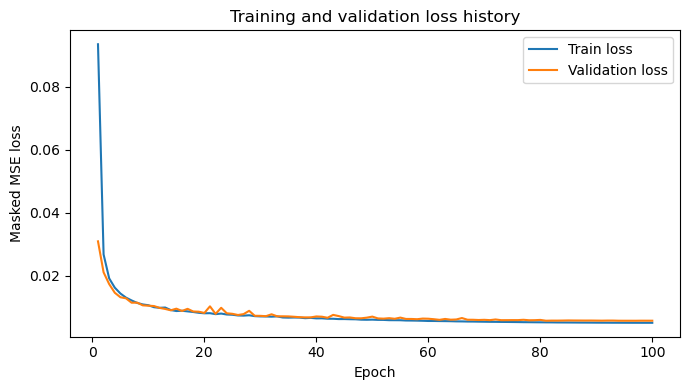

In [23]:
def plot_loss_history(history):
    train_hist = history.get("train_loss", [])
    val_hist = history.get("val_loss", [])

    if len(train_hist) == 0 and len(val_hist) == 0:
        print("No saved training history found in checkpoint.")
        return

    print(f"Loss history lengths - train: {len(train_hist)}, val: {len(val_hist)}")

    plt.figure(figsize=(7, 4))
    plt.plot(np.arange(1, len(train_hist)+1), train_hist, label='Train loss')
    plt.plot(np.arange(1, len(val_hist)+1), val_hist, label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Masked MSE loss')
    plt.title('Training and validation loss history')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss_history(history)

In [24]:
# history_npz_path = os.path.join(CHECKPOINT_DIR, f"resnet_loss_history_{RUN_TIMESTAMP}.npz")
# np.savez(
#     history_npz_path,
#     train_loss=np.array(history["train_loss"]),
#     val_loss=np.array(history["val_loss"]),
# )
# print(f"Saved loss history to {history_npz_path}")

### Forward pass

In [25]:
# checkpoint = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
checkpoint = load_checkpoint_with_history(best_model_path)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded best model from epoch {checkpoint['epoch']} with val_loss={checkpoint['val_loss']:.4f}")

Loaded best model from epoch 97 with val_loss=0.0057


### Test loss

In [26]:
def evaluate_split(model, inputs, targets, land_mask, batch_size, split_name):
    model.eval()
    running_loss = 0.0
    n_batches = 0
    last_output = None
    last_target = None
    last_mask = None

    with torch.no_grad():
        for xb, yb, mb in iterate_batches(
            inputs, targets, land_mask, batch_size, shuffle=False
        ):
            output = model(xb)
            loss = criterion(output, yb, mb)

            running_loss += loss.item()
            n_batches += 1

            last_output = output.detach().cpu()
            last_target = yb.detach().cpu()
            last_mask = mb.detach().cpu()

    loss_value = running_loss / max(n_batches, 1)
    print(f"{split_name} loss: {loss_value:.4f}")

    if last_output is not None:
        print(f"{split_name} output shape: {tuple(last_output.shape)}")
        print(f"{split_name} target shape: {tuple(last_target.shape)}")
        print(f"{split_name} shapes match: {tuple(last_output.shape) == tuple(last_target.shape)}")
        print(
            f"{split_name} output stats: "
            f"mean={last_output.mean().item():.4f}, "
            f"std={last_output.std().item():.4f}"
        )
        print(f"{split_name} output has NaN: {torch.isnan(last_output).any().item()}")
        print(f"{split_name} output has Inf: {torch.isinf(last_output).any().item()}")

    return {
        "loss": loss_value,
        "last_output": last_output,
        "last_target": last_target,
        "last_mask": last_mask,
    }

print(f"Evaluation RUN_MODE = {RUN_MODE}")

if RUN_MODE != "eval":
    val_eval = evaluate_split(
        model,
        val_input_tensor,
        val_target_tensor,
        val_land_mask,
        BATCH_SIZE,
        "Validation",
    )
    val_loss_eval = val_eval["loss"]
else: 
    print("Skipping validation split because RUN_MODE == 'eval'")
    val_eval = None
    val_loss_eval = None


test_recon_eval = evaluate_split(
    model,
    test_recon_input_tensor,
    test_recon_target_tensor,
    test_recon_land_mask,
    BATCH_SIZE,
    f"Test ({TEST_MODEL}, 1993-2024)",
)

test_full_eval = evaluate_split(
    model,
    test_full_input_tensor,
    test_full_target_tensor,
    test_full_land_mask,
    BATCH_SIZE,
    f"Test ({TEST_MODEL}, 1850-2100)",
)

test_recon_loss = test_recon_eval["loss"]
test_full_loss = test_full_eval["loss"]

Evaluation RUN_MODE = train


Validation loss: 0.0057
Validation output shape: (32, 1, 180, 360)
Validation target shape: (32, 1, 180, 360)
Validation shapes match: True
Validation output stats: mean=0.2092, std=0.5044
Validation output has NaN: False
Validation output has Inf: False


Test (UKESM1-0-LL, 1993-2024) loss: 0.0252
Test (UKESM1-0-LL, 1993-2024) output shape: (32, 1, 180, 360)
Test (UKESM1-0-LL, 1993-2024) target shape: (32, 1, 180, 360)
Test (UKESM1-0-LL, 1993-2024) shapes match: True
Test (UKESM1-0-LL, 1993-2024) output stats: mean=0.2030, std=0.4342
Test (UKESM1-0-LL, 1993-2024) output has NaN: False
Test (UKESM1-0-LL, 1993-2024) output has Inf: False


Test (UKESM1-0-LL, 1850-2100) loss: 0.0285
Test (UKESM1-0-LL, 1850-2100) output shape: (4, 1, 180, 360)
Test (UKESM1-0-LL, 1850-2100) target shape: (4, 1, 180, 360)
Test (UKESM1-0-LL, 1850-2100) shapes match: True
Test (UKESM1-0-LL, 1850-2100) output stats: mean=1.6716, std=0.5127
Test (UKESM1-0-LL, 1850-2100) output has NaN: False
Test (UKESM1-0-LL, 1850-2100) output has Inf: False


### Helper functions

In [27]:
def denormalise(x, mean, std):
    return x * std + mean

def predict_in_batches(model, input_tensor, batch_size):
    model.eval()
    n = input_tensor.shape[0]
    preds = np.empty((n, 1, input_tensor.shape[2], input_tensor.shape[3]), dtype=np.float32)
    
    with torch.no_grad():
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            xb = input_tensor[start:end].to(DEVICE)
            out = model(xb).detach().cpu().numpy().astype(np.float32)
            preds[start:end] = out
            del xb, out  # free memory
            
    return preds

def masked_flatten(data, ocean_mask):
    flat = data[ocean_mask]
    return flat[np.isfinite(flat)]

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    bias = np.mean(y_pred - y_true)

    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        corr = np.corrcoef(y_true, y_pred)[0, 1]
    else:
        corr = np.nan

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "Corr": float(corr),
        "Bias": float(bias),
    }


def summarise_distribution(name, arr):
    arr = np.asarray(arr)
    arr = arr[np.isfinite(arr)]

    stats = {
        "min": float(np.min(arr)),
        "max": float(np.max(arr)),
        "mean": float(np.mean(arr)),
        "std": float(np.std(arr)),
        "median": float(np.median(arr)),
        "q01": float(np.quantile(arr, 0.01)),
        "q05": float(np.quantile(arr, 0.05)),
        "q95": float(np.quantile(arr, 0.95)),
        "q99": float(np.quantile(arr, 0.99)),
    }

    print(
        f"{name}: "
        f"min={stats['min']:.2f}, max={stats['max']:.2f}, "
        f"mean={stats['mean']:.2f}, std={stats['std']:.2f}, "
        f"median={stats['median']:.2f}, "
        f"q01={stats['q01']:.2f}, q05={stats['q05']:.2f}, "
        f"q95={stats['q95']:.2f}, q99={stats['q99']:.2f}"
    )
    return stats

def masked_mean_map(data, land_mask):
    data = np.asarray(data)
    mask = np.asarray(land_mask)

    if data.ndim == 4:
        field = data[:, 0, :, :]
    elif data.ndim == 3:
        field = data
    elif data.ndim == 2:
        field = data[None, :, :]
    else:
        raise ValueError(f"Unexpected data shape: {data.shape}")

    if mask.ndim == 4:
        ocean = mask[:, 0, :, :] == 0
    elif mask.ndim == 3 or mask.ndim == 2:
        ocean = mask == 0
    else:
        raise ValueError(f"Unexpected mask shape: {mask.shape}")

    masked = np.where(ocean, field, np.nan)
    
    return np.nanmean(masked, axis=0)
    # # masked = np.where(land_mask[:, 0], np.nan, data[:, 0])
    # # return np.nanmean(masked, axis=0)
    # field = data[:, 0] if data.ndim==4 else data
    # masked = np.where(land_mask>0, np.nan, field)
    # count = np.sum(np.isfinite(masked), axis=0)
    # out = np.full(masked.shape[1:], np.nan, dtype=np.float32)
    # np.divide(np.nansum(masked, axis=0), count, out=out, where=count>0)

    # return out

### Satellite inference
Run ResNet inference on all satellite months: 1993–2024

In [28]:
if USE_SATELLITE:
    sat_input_tensor_full = torch.from_numpy(sat_input_stack)

    sat_pred_norm_np = predict_in_batches(
        model,
        sat_input_tensor_full,
        BATCH_SIZE,
    )

    sat_pred_resid_np = denormalise(
        sat_pred_norm_np,
        target_means[0],
        target_stds[0],
    )

    print("Full satellite input tensor:", sat_input_tensor_full.shape)
    print("Full satellite residual prediction shape:", sat_pred_resid_np.shape)
    print("Residual prediction has NaN:", np.isnan(sat_pred_resid_np).any())
    print("Residual prediction has Inf:", np.isinf(sat_pred_resid_np).any())

    # Build valid-inference mask
    # sat_full_invalid_mask is True where one or more input
    # covariates are missing - inverting it to obtain valid cells
    sat_valid_ocean_da = xr.DataArray(
        ~sat_full_invalid_mask[:, 0, :, :],
        coords={
            "time": ds_sat.time.values,
            "lat": ds_sat.lat.values,
            "lon": ds_sat.lon.values,
        },
        dims=("time", "lat", "lon"),
        name="valid_ocean_mask",
        attrs={
            "long_name": (
                "Valid satellite inference mask based on "
                "complete input predictor availability"
            ),
            "flag_values": np.array( [0, 1], dtype=np.int8),
            "flag_meanings": "invalid valid",
        }
    )

    # Convert ResNet residual prediction to xarray
    sat_full_pred_resid = xr.DataArray(
        sat_pred_resid_np[:, 0, :, :],
        coords={
            "time": ds_sat.time.values,
            "lat": ds_sat.lat.values,
            "lon": ds_sat.lon.values,
        },
        dims=("time", "lat", "lon"),
        name="pco2_nonthermal_pred",
        attrs={
            "long_name": (
                "ResNet-predicted non-thermal pCO2 component"
            ),
            "units": "uatm",
        },
    )

    # Confirm residual and thermal fields use identical grids
    assert np.array_equal(
        sat_full_pred_resid.time.values,
        pco2_thermal_full.time.values,
    ), "Residual and thermal time coordinates do not match."

    assert np.array_equal(
        sat_full_pred_resid.lat.values,
        pco2_thermal_full.lat.values,
    ), "Residual and thermal latitude coordinates do not match."

    assert np.array_equal(
        sat_full_pred_resid.lon.values,
        pco2_thermal_full.lon.values,
    ), "Residual and thermal longitude coordinates do not match."

    # Apply the same valid-inference mask to both components
    sat_full_pred_resid = sat_full_pred_resid.where(sat_valid_ocean_da)

    sat_thermal_full = (
        pco2_thermal_full
        .where(sat_valid_ocean_da)
        .rename("pco2_thermal")
    )

    sat_thermal_full.attrs.update({
        "long_name": "XGBoost-derived thermal pCO2 component",
        "units": "uatm",
    })

    # Total prediction: non-thermal ResNet + thermal component
    sat_full_pred_total = (
        sat_full_pred_resid
        + sat_thermal_full
    ).rename("pco2_total_pred")

    sat_full_pred_total.attrs.update({
        "long_name": "Total predicted surface-ocean pCO2",
        "units": "uatm",
        "formula": "pco2_nonthermal_pred + pco2_thermal",
    })

    # Check decomposition before saving
    expected_total = (
        sat_full_pred_resid
        + sat_thermal_full
    )

    finite_total = (
        np.isfinite(expected_total.values)
        & np.isfinite(sat_full_pred_total.values)
    )

    assert np.allclose(
        expected_total.values[finite_total],
        sat_full_pred_total.values[finite_total],
        rtol=1e-5,
        atol=1e-5,
    )

    print("Prediction decomposition check passed: total = residual + thermal")

    # Summary distributions across valid inference cells
    sat_ocean_full = sat_valid_ocean_da.values

    sat_pred_flat_full = masked_flatten(
        sat_full_pred_resid.values,
        sat_ocean_full,
    )

    sat_total_flat_full = masked_flatten(
        sat_full_pred_total.values,
        sat_ocean_full,
    )

    sat_full_time = np.asarray(ds_sat.time.values).astype("datetime64[ns]")

    # In-memory output Dataset; member specific Zarr is saved later
    sat_full_ds = xr.Dataset(
        data_vars={
            "pco2_nonthermal_pred": (
                sat_full_pred_resid.astype(np.float32)
            ),
            "pco2_thermal": (
                sat_thermal_full.astype(np.float32)
            ),
            "pco2_total_pred": (
                sat_full_pred_total.astype(np.float32)
            ),
            "ocean_mask": (
                sat_valid_ocean_da.astype(np.int8)
            )
        },
        coords={
            "time": ds_sat.time.values,
            "lat": ds_sat.lat.values,
            "lon": ds_sat.lon.values,
        },
        attrs={
            "title": (
                "Satellite ResNet pCO2 inference with "
                "XGBoost-derived thermal component"
            ),
            "note": (
                "pco2_total_pred = pco2_nonthermal_pred "
                "+ pco2_thermal"
            ),
            "thermal_source": "05_xgboost_climatology.ipynb output",
            "time_coverage": (
                f"{str(ds_sat.time.values[0])[:10]} to "
                f"{str(ds_sat.time.values[-1])[:10]}"
            )
        }
    )

    print("Satellite dataset variables:", list(sat_full_ds.data_vars))
    print("Full total prediction shape:", sat_full_ds["pco2_total_pred"].shape)
    print("Full total prediction has NaN:", np.isnan(sat_full_pred_total.values).any())
    print("Full total prediction has Inf:", np.isinf(sat_full_pred_total.values).any())

    print("\nSatellite distribution stats")
    summarise_distribution("Satellite residual prediction", sat_pred_flat_full)
    summarise_distribution("Satellite total pCO2 prediction", sat_total_flat_full)

Full satellite input tensor: torch.Size([384, 11, 180, 360])
Full satellite residual prediction shape: (384, 1, 180, 360)
Residual prediction has NaN: False
Residual prediction has Inf: False


Prediction decomposition check passed: total = residual + thermal


Satellite dataset variables: ['pco2_nonthermal_pred', 'pco2_thermal', 'pco2_total_pred', 'ocean_mask']
Full total prediction shape: (384, 180, 360)
Full total prediction has NaN: True


Full total prediction has Inf: False

Satellite distribution stats


Satellite residual prediction: min=-566.30, max=350.59, mean=-5.49, std=30.94, median=-4.79, q01=-95.06, q05=-55.38, q95=40.39, q99=61.82


Satellite total pCO2 prediction: min=-543.64, max=379.54, mean=-5.33, std=31.17, median=-4.99, q01=-93.74, q05=-55.48, q95=41.38, q99=60.87


### Remove unused variables from memory
Checks if they exist which depends on train/resume/val mode.

In [29]:
for name in [
    "train_input_stack", "train_target_stack",
    "val_input_stack",
    "test_recon_input_stack",
    "test_full_input_stack",
    "train_input_norm", "train_target_norm", "val_target_tensor",
    "sat_input_stack", "sat_input_tensor_full", 
]:
    if name in globals(): # check if exists
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [30]:
if RUN_MODE != "eval":
    val_pred_norm = predict_in_batches(model, val_input_tensor, BATCH_SIZE)

    val_pred_resid = denormalise(val_pred_norm, target_means[0], target_stds[0])
    val_true_resid = denormalise(val_target_stack, target_means[0], target_stds[0])

    val_ocean = ~val_land_mask[:, 0]

    val_true_flat = masked_flatten(val_true_resid[:, 0], val_ocean)
    val_pred_flat = masked_flatten(val_pred_resid[:, 0], val_ocean)
    val_resid_flat = val_true_flat - val_pred_flat

    print("Validation metrics:", regression_metrics(val_true_flat, val_pred_flat))

    print("\nValidation distribution stats")
    summarise_distribution("Validation truth", val_true_flat)
    summarise_distribution("Validation prediction", val_pred_flat)
    summarise_distribution("Validation residual (truth - prediction)", val_resid_flat)
else:
    val_pred_norm = val_pred_resid = val_true_resid = None
    val_ocean = val_true_flat = val_pred_flat = val_resid_flat = None

test_recon_pred_norm = predict_in_batches(model, test_recon_input_tensor, BATCH_SIZE)
test_full_pred_norm = predict_in_batches(model, test_full_input_tensor, BATCH_SIZE)

test_recon_pred_resid = denormalise(test_recon_pred_norm, target_means[0], target_stds[0])
test_recon_true_resid = denormalise(test_recon_target_norm, target_means[0], target_stds[0])

test_full_pred_resid = denormalise(test_full_pred_norm, target_means[0], target_stds[0])
test_full_true_resid = denormalise(test_full_target_norm, target_means[0], target_stds[0])

# total = resid + thermal
test_recon_true_total = test_recon_true_resid + test_recon_thermal_stack
test_recon_pred_total = test_recon_pred_resid + test_recon_thermal_stack

test_full_true_total = test_full_true_resid + test_full_thermal_stack
test_full_pred_total = test_full_pred_resid + test_full_thermal_stack

test_recon_ocean = ~test_recon_land_mask[:, 0]
test_full_ocean = ~test_full_land_mask[:, 0]

test_recon_time = np.array(test_dataset_recon["time"].values).astype("datetime64[ns]")
test_full_time = np.array(test_dataset_full["time"].values).astype("datetime64[ns]")

print("test_recon_time range:", test_recon_time.min(), "to", test_recon_time.max(), "n =", len(test_recon_time))
print("test_full_time range:", test_full_time.min(), "to", test_full_time.max(), "n =", len(test_full_time))

test_recon_true_flat = masked_flatten(test_recon_true_resid[:, 0], test_recon_ocean)
test_recon_pred_flat = masked_flatten(test_recon_pred_resid[:, 0], test_recon_ocean)
test_recon_resid_flat = test_recon_true_flat - test_recon_pred_flat

test_full_true_flat = masked_flatten(test_full_true_resid[:, 0], test_full_ocean)
test_full_pred_flat = masked_flatten(test_full_pred_resid[:, 0], test_full_ocean)
test_full_resid_flat = test_full_true_flat - test_full_pred_flat

print("\nTest reconstruction metrics:", regression_metrics(test_recon_true_flat, test_recon_pred_flat))
print("Test full metrics:", regression_metrics(test_full_true_flat, test_full_pred_flat))

print("\nReconstruction-period distribution stats")
summarise_distribution("Reconstruction truth", test_recon_true_flat)
summarise_distribution("Reconstruction prediction", test_recon_pred_flat)
summarise_distribution("Reconstruction residual (truth - prediction)", test_recon_resid_flat)

print("\nFull-period distribution stats")
summarise_distribution("Full truth", test_full_true_flat)
summarise_distribution("Full prediction", test_full_pred_flat)
summarise_distribution("Full residual (truth - prediction)", test_full_resid_flat)

if USE_SATELLITE:
    print("\nSatellite distribution stats")
    print("Full satellite months:", len(sat_full_time))
    print("Full satellite first/last month:", str(sat_full_time[0])[:10], "to", str(sat_full_time[-1])[:10])
    print("Full satellite ocean points:", sat_pred_flat_full.size)
    summarise_distribution("Satellite full prediction", sat_pred_flat_full)

Validation metrics: {'MAE': 5.821747779846191, 'RMSE': 8.487897872924805, 'Corr': 0.9618106345798841, 'Bias': -1.0280866622924805}

Validation distribution stats


Validation truth: min=-1010.29, max=1135.46, mean=-4.81, std=30.78, median=-4.55, q01=-88.86, q05=-52.21, q95=40.61, q99=69.06


Validation prediction: min=-935.64, max=1147.39, mean=-5.83, std=29.65, median=-6.01, q01=-85.59, q05=-51.07, q95=38.43, q99=65.52


Validation residual (truth - prediction): min=-718.72, max=495.47, mean=1.03, std=8.43, median=1.12, q01=-22.27, q05=-11.55, q95=13.14, q99=24.27


test_recon_time range: 1993-01-16T00:00:00.000000000 to 2024-12-16T00:00:00.000000000 n = 384
test_full_time range: 1850-01-16T00:00:00.000000000 to 2100-12-16T00:00:00.000000000 n = 3012


...

Reconstruction residual (truth - prediction): min=-272.49, max=715.81, mean=-0.85, std=19.20, median=0.99, q01=-63.80, q05=-33.95, q95=22.00, q99=49.04

Full-period distribution stats


Full truth: min=-439.49, max=1320.63, mean=-1.54, std=91.89, median=-36.50, q01=-133.09, q05=-102.68, q95=177.87, q99=223.71


Full prediction: min=-322.10, max=508.67, mean=-1.47, std=91.77, median=-35.71, q01=-128.42, q05=-103.23, q95=180.45, q99=217.06


Full residual (truth - prediction): min=-413.99, max=1145.55, mean=-0.07, std=18.65, median=-0.04, q01=-52.30, q05=-26.38, q95=26.50, q99=55.65

Satellite distribution stats
Full satellite months: 384
Full satellite first/last month: 1993-01-01 to 2024-12-01
Full satellite ocean points: 12037249


Satellite full prediction: min=-566.30, max=350.59, mean=-5.49, std=30.94, median=-4.79, q01=-95.06, q05=-55.38, q95=40.39, q99=61.82


### Save predictions

In [31]:
def save_prediction_member(pred_resid, pred_thermal, pred_total, land_mask, lats, lons, time_values, member_id, seed, save_path, attrs=None):
    """
    Save one ensemble member with residual, thermal, and total pco2.
    All fields use dims (member, time, lat, lon)
    """
    coords = {
        "member": [member_id],
        "time": time_values,
        "lat": lats,
        "lon": lons,
    }

    ds_out = xr.Dataset(
        {
            "pco2_nonthermal_pred": xr.DataArray(
                pred_resid[np.newaxis, ...].astype(np.float32),
                dims=("member", "time", "lat", "lon"),
                coords=coords,
            ),
            "pco2_thermal": xr.DataArray(
                pred_thermal[np.newaxis, ...].astype(np.float32),
                dims=("member", "time", "lat", "lon"),
                coords=coords,
            ),
            "pco2_total_pred": xr.DataArray(
                pred_total[np.newaxis, ...].astype(np.float32),
                dims=("member", "time", "lat", "lon"),
                coords=coords,
            ),
            "land_mask": xr.DataArray(
                land_mask[np.newaxis, :, 0, :, :].astype(np.int8),
                dims=("member", "time", "lat", "lon"),
                coords=coords,
            ),
        }
    )

    ds_out["pco2_nonthermal_pred"].attrs["units"] = "uatm"
    ds_out["pco2_thermal"].attrs["units"] = "uatm"
    ds_out["pco2_total_pred"].attrs["units"] = "uatm"

    ds_out.attrs.update({
        "member_id": int(member_id),
        "seed": int(seed),
        "time_coverage": f"{str(time_values[0])[:10]} to {str(time_values[-1])[:10]}"
    })

    if attrs is not None:
        ds_out.attrs.update(attrs)

    if os.path.exists(save_path):
        shutil.rmtree(save_path)

    ds_out.to_zarr(
        save_path,
        mode="w",
        consolidated=True,
    )

    # Reopen immediately to verify saved member
    with xr.open_zarr(save_path,  consolidated=True) as check:
        assert check.sizes["member"] == 1
        assert check.sizes["time"] == len(time_values)
        assert check.sizes["lat"] == len(lats)
        assert check.sizes["lon"] == len(lons)

        assert int(check.attrs["member_id"]) == int(member_id)
        assert int(check.attrs["seed"]) == int(seed)

        assert set(check.data_vars) == {
            "pco2_nonthermal_pred",
            "pco2_thermal",
            "pco2_total_pred",
            "land_mask",
        }

        assert check["pco2_thermal"].attrs["units"] == "uatm"
        assert check["pco2_total_pred"].attrs["units"] == "uatm"

    print(f"Saved member {member_id}, seed {seed}: {save_path}")

### Call to save this member's own zarr store

Each PBS array member has a distinct PRED_SAVE_PATH so no other member can overwrite these attributes.

In [32]:
# check 
assert MEMBER_ID in range(10)
assert SEED == BASE_SEED + MEMBER_ID

assert sat_full_pred_resid.sizes == {
    "time": len(ds_sat.time),
    "lat": len(ds_sat.lat),
    "lon": len(ds_sat.lon),
}

assert pco2_thermal_full.sizes == sat_full_pred_resid.sizes
assert sat_full_pred_total.sizes == sat_full_pred_resid.sizes

print(f"Ready to save member {MEMBER_ID} with seed {SEED}")

Ready to save member 0 with seed 42


In [33]:
PRED_SAVE_DIR = os.path.join(DATA_ROOT, "predictions", "prior", "ensemble_members")

os.makedirs(PRED_SAVE_DIR, exist_ok=True)

PRED_SAVE_PATH = os.path.join(PRED_SAVE_DIR, f"resnet_satellite_pco2_member{MEMBER_ID}_seed{SEED}.zarr")

checkpoint_best = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=False,
)

member_metadata = {
    "title": (
        "ResNet satellite pCO2 prediction with "
        "XGBoost-derived thermal component"
    ),
    "member_id": int(MEMBER_ID),
    "seed": int(SEED),
    "best_epoch": int(checkpoint_best["epoch"]),
    "best_val_loss": float(checkpoint_best["best_val_loss"]),
    "architecture": "PeriodicResNet(hidden_channels=32, n_res_blocks=4)",
    "channel_order": list(all_covariate_names),
    "target_variable": TARGET_VAR,
    "test_model": TEST_MODEL,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "longitude_convention": "-180 to +180",
    "thermal_source": "pco2_thermal_xgboost_1993_2024_1deg_monthly.zarr",
    "model_checkpoint": best_model_path,
    "run_timestamp": checkpoint_best.get(
        "run_timestamp",
        RUN_TIMESTAMP,
    ),
    "note": "pco2_total_pred = pco2_nonthermal_pred + pco2_thermal"
}

save_prediction_member(
    pred_resid=sat_full_pred_resid.values, # xarray
    pred_thermal=sat_thermal_full.values,  # xarray masked
    pred_total=sat_full_pred_total.values, # xarrat masked
    land_mask=sat_full_invalid_mask,       # numpy boolean array
    lats=lats,
    lons=lons,
    time_values=ds_sat.time.values,
    member_id=MEMBER_ID,
    seed=SEED,
    save_path=PRED_SAVE_PATH,
    attrs=member_metadata,
)

Saved member 0, seed 42: /rds/general/user/efs25/home/irp-efs25/data/predictions/prior/ensemble_members/resnet_satellite_pco2_member0_seed42.zarr


## 3. Visualisations
Separate diagnostics for validation, UKESM reconstruction (1993-2024) with and without satellite data, and full UKESM period (1850-2100).

### Distribution plots

In [34]:
def plot_distribution_diagnostics(
    distributions,
    labels,
    period_name,
    save_name,
    *,
    panel2_data=None,
    panel2_title="",
    panel2_xlabel="",
    panel2_color="tab:red",
    panel2_zero_line=True,
    xlabel="pCO₂ residual (µatm)",
    ylabel="Density",
    boxplot_ylabel=None,
    suptitle_prefix="Distribution diagnostics",
    bins_hist=100,
    bins_panel2=100,
    hist_colors=None,
    density=True,
    showfliers=True,
):
    """
    Generic distribution diagnostics.

    Parameters
    ----------
    distributions : list[array-like]
        Data to compare in histogram and boxplot.
    labels : list[str]
        Labels for each distribution.
    panel2_data : array-like or None
        Data for middle panel (e.g. residuals or differences).
        If None, middle panel is left blank.
    """

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: distributions
    if hist_colors is None:
        hist_colors = [None] * len(distributions)

    for data, label, color in zip(distributions, labels, hist_colors):
        data = np.asarray(data)
        data = data[np.isfinite(data)]

        axes[0].hist(
            data,
            bins=bins_hist,
            alpha=0.6,
            density=density,
            label=label,
            color=color,
        )

    axes[0].set_title(f"{period_name}: distributions")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel)
    axes[0].legend()

    # Panel 2: optional histogram
    if panel2_data is not None:
        panel2_data = np.asarray(panel2_data)
        panel2_data = panel2_data[np.isfinite(panel2_data)]

        axes[1].hist(
            panel2_data,
            bins=bins_panel2,
            alpha=0.8,
            density=density,
            color=panel2_color,
        )

        if panel2_zero_line:
            axes[1].axvline(0, color="k", linestyle="--", linewidth=1)

        axes[1].set_title(panel2_title)
        axes[1].set_xlabel(panel2_xlabel)
        axes[1].set_ylabel(ylabel)
    else:
        axes[1].axis("off")

    # Panel 3: boxplots
    box_data = [
        np.asarray(d)[np.isfinite(d)]
        for d in distributions
    ]

    axes[2].boxplot(
        box_data,
        labels=labels,
        showfliers=showfliers,
        vert=True,
    )

    axes[2].set_title(f"{period_name}: box plots")
    axes[2].set_ylabel(boxplot_ylabel or xlabel)

    plt.suptitle(f"{suptitle_prefix} - {period_name}", y=1.02)
    plt.tight_layout()

    save_path = os.path.join(FIGURES_DIR, save_name)
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved figure to: {save_path}")

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/244451621.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


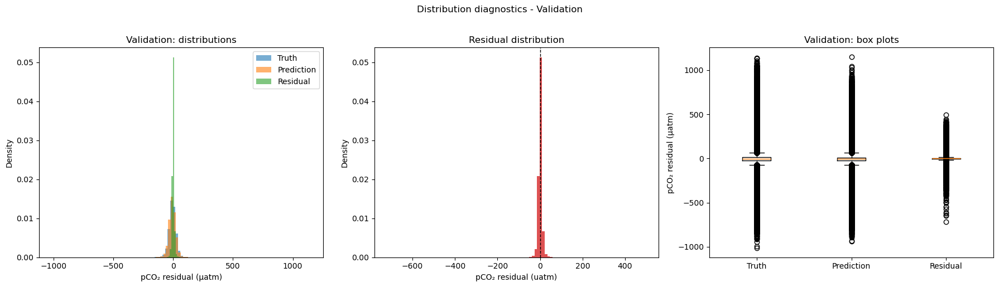

Saved figure to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_validation_distribution_diagnostics.png


/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/244451621.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


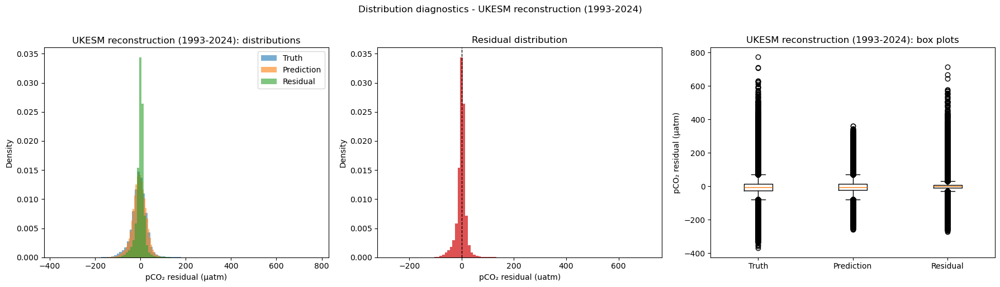

Saved figure to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_reconstruction_distribution_diagnostics.png


/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/244451621.py:88: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(


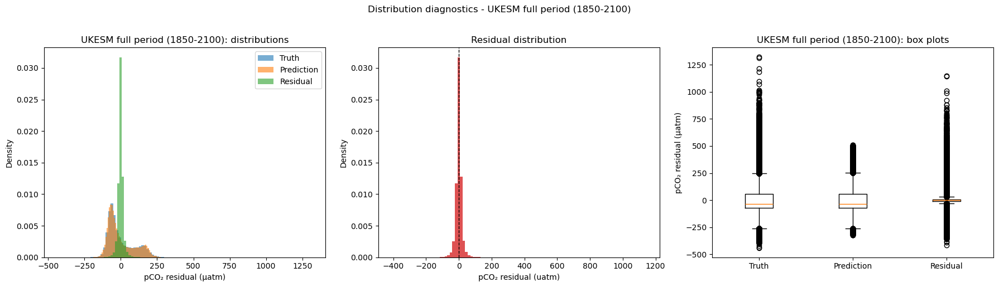

Saved figure to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_full_distribution_diagnostics.png


In [35]:
if RUN_MODE != "eval":
    plot_distribution_diagnostics(
        distributions=[val_true_flat, val_pred_flat, val_resid_flat],
        labels=["Truth", "Prediction", "Residual"],
        period_name="Validation",
        save_name="resnet_validation_distribution_diagnostics.png",
        panel2_data=val_resid_flat,
        panel2_title="Residual distribution",
        panel2_xlabel="pCO₂ residual (uatm)",
    )

plot_distribution_diagnostics(
    distributions=[test_recon_true_flat, test_recon_pred_flat, test_recon_resid_flat],
    labels=["Truth", "Prediction", "Residual"],
    period_name="UKESM reconstruction (1993-2024)",
    save_name="resnet_reconstruction_distribution_diagnostics.png",
    panel2_data=test_recon_resid_flat,
    panel2_title="Residual distribution",
    panel2_xlabel="pCO₂ residual (uatm)",
)

plot_distribution_diagnostics(
    distributions=[test_full_true_flat, test_full_pred_flat, test_full_resid_flat],
    labels=["Truth", "Prediction", "Residual"],
    period_name="UKESM full period (1850-2100)",
    save_name="resnet_full_distribution_diagnostics.png",
    panel2_data=test_full_resid_flat,
    panel2_title="Residual distribution",
    panel2_xlabel="pCO₂ residual (uatm)",
)

### Mean map plot over given period (full, seasonal, monthly)

In [36]:
def get_season_mask(times, season):
    times = pd.to_datetime(times)
    season_months = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}
    return np.isin(times.month, season_months[season])

def get_month_mask(times, month):
    return pd.to_datetime(times).month == month

def find_extreme_outliers(arr, lats, lons, label, pct=99, top_n=15):
    finite_mask = np.isfinite(arr)
    vals = arr[finite_mask]

    if vals.size == 0:
        print(f"[{label}] no finite values, skipping outlier check")
        return None, None
    
    thresh = np.nanpercentile(np.abs(vals), pct)
    outlier_mask = finite_mask & (np.abs(arr) >= thresh)
    lat_idx, lon_idx = np.where(outlier_mask)

    outlier_records = []
    for i in range(len(lat_idx)):
        row = lat_idx[i]
        col = lon_idx[i]
        lat_value = lats[row]
        lon_value = lons[col]
        data_value = arr[row, col]
        abs_value = abs(data_value)
        outlier_records.append((abs_value, lat_value, lon_value, data_value))

    outlier_records.sort(reverse=True)

    print(f"\n[{label}] top {100-pct}% outliers (|value| >= {thresh:.2f}), n={len(outlier_records)}")

    for record in outlier_records[:top_n]:
        abs_value, lat_value, lon_value, data_value = record
        print(f"  lat={lat_value:7.2f} lon={lon_value:7.2f} value={data_value:8.2f}")

    return outlier_mask, thresh

In [37]:
def plot_mean_comparison_maps(
    array_a, land_mask_a, title_a,
    array_b, land_mask_b, title_b,
    lats, lons,
    suptitle,
    save_name,
    diff_title="Difference",
    diff_order="b_minus_a",       # "b_minus_a" or "a_minus_b"
    cbar_mode="Residual",
    diff_cbar_label="Difference (uatm)",
    cmap="RdBu_r",
    land_color="#d0d0d0",
    diff_symmetric=True,          # keep the diff panel centered at 0 or not
    label_a="A",
    label_b="B",
    time_a=None,
    time_b=None,
    mode="annual",       # "annual", "season", "month"
    season=None,         # "DJF", "MAM", "JJA", "SON"
    month=None,          # 1-12
    outlier_pct=98,      # top (100-pct)% by |value| flagged as outliers
):
    if mode == "season":
        if season is None:
            raise ValueError("season must be specified when mode='season'")
        mask_a = get_season_mask(time_a, season)
        mask_b = get_season_mask(time_b, season)
        array_a = array_a[mask_a]
        land_mask_a = land_mask_a[mask_a]
        array_b = array_b[mask_b]
        land_mask_b = land_mask_b[mask_b]
    elif mode == "month":
        if month is None:
            raise ValueError("month must be specified when mode='month'")
        mask_a = get_month_mask(time_a, month)
        mask_b = get_month_mask(time_b, month)
        array_a = array_a[mask_a]
        land_mask_a = land_mask_a[mask_a]
        array_b = array_b[mask_b]
        land_mask_b = land_mask_b[mask_b]
    elif mode != "annual":
        raise ValueError(f"Unknown mode: {mode}")

    mean_a = np.asarray(masked_mean_map(array_a, land_mask_a)).squeeze()
    mean_b = np.asarray(masked_mean_map(array_b, land_mask_b)).squeeze()

    if diff_order == "b_minus_a":
        diff_mean = mean_b - mean_a
    else:
        diff_mean = mean_a - mean_b

    lats = np.asarray(lats).squeeze()
    lons = np.asarray(lons).squeeze()

    for name, arr in [("mean_a", mean_a), ("mean_b", mean_b), ("diff_mean", diff_mean)]:
        if arr.ndim != 2:
            raise ValueError(f"{name} must be 2D (lat, lon), got shape {arr.shape}")

    expected_shape = (len(lats), len(lons))
    if mean_a.shape != expected_shape:
        raise ValueError(
            f"Map shape {mean_a.shape} does not match (len(lats), len(lons))={expected_shape}"
        )

    outlier_mask_a, thresh_a = find_extreme_outliers(mean_a, lats, lons, f"{label_a} ({suptitle})", pct=outlier_pct)
    outlier_mask_b, thresh_b = find_extreme_outliers(mean_b, lats, lons, f"{label_b} ({suptitle})", pct=outlier_pct)
    outlier_mask_diff, thresh_diff = find_extreme_outliers(diff_mean, lats, lons, f"diff ({suptitle})", pct=outlier_pct)

    combined_outlier_mask = outlier_mask_a | outlier_mask_b | outlier_mask_diff
    outlier_display = np.where(combined_outlier_mask, diff_mean, np.nan)
    n_outliers = int(np.sum(combined_outlier_mask))
    print(f"\nTotal combined outlier pixels across A/B/diff: {n_outliers}")

    def data_range(arr, pmin=2, pmax=98):
        finite = arr[np.isfinite(arr)]
        # return np.nanmin(finite), np.nanmax(finite)
        return np.nanpercentile(finite, pmin), np.nanpercentile(finite, pmax)

    a_vmin, a_vmax = data_range(mean_a)
    b_vmin, b_vmax = data_range(mean_b)

    if diff_symmetric:
        dabs = np.nanmax(np.abs(diff_mean[np.isfinite(diff_mean)]))
        d_vmin, d_vmax = -dabs, dabs
    else:
        d_vmin, d_vmax = data_range(diff_mean)

    # fig, axes = plt.subplots(1, 3, figsize=(24, 7), subplot_kw={"projection": ccrs.Robinson()})
    # 4-panel with A, B, diff + outlier map
    fig, axes = plt.subplots(1, 4, figsize=(30, 7), subplot_kw={"projection": ccrs.Robinson()})

    cbar_label = cbar_mode + " pCO2 (uatm)"
    plot_specs = [
        (mean_a, title_a, cmap, a_vmin, a_vmax, cbar_label),
        (mean_b, title_b, cmap, b_vmin, b_vmax, cbar_label),
        (diff_mean, diff_title, cmap, d_vmin, d_vmax, diff_cbar_label),
    ]

    for ax, (data, title, cm, vmin, vmax, cbar_label_i) in zip(axes[:3], plot_specs):
        im = ax.pcolormesh(
            lons, lats, data,
            transform=ccrs.PlateCarree(),
            cmap=cm, vmin=vmin, vmax=vmax,
            shading="auto",
        )
        ax.add_feature(cfeature.LAND, color=land_color, zorder=3)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
        ax.set_title(title, fontsize=12)
        plt.colorbar(im, ax=ax, shrink=0.68, pad=0.03, label=cbar_label_i)

    # 4th = outlier locations coloured by diff value - everything else greyed out
    ax_out = axes[3]
    ax_out.pcolormesh(
        lons, lats, np.zeros_like(diff_mean),
        transform=ccrs.PlateCarree(),
        cmap="Greys", vmin=0, vmax=1, shading="auto", alpha=0.15,
    )
    im_out = ax_out.pcolormesh(
        lons, lats, outlier_display,
        transform=ccrs.PlateCarree(),
        cmap=cmap, vmin=d_vmin, vmax=d_vmax,
        shading="auto",
    )
    ax_out.add_feature(cfeature.LAND, color=land_color, zorder=3)
    ax_out.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=4)
    ax_out.set_title(f"Outlier pixels (top {100-outlier_pct}%, n={n_outliers})", fontsize=12)
    plt.colorbar(im_out, ax=ax_out, shrink=0.68, pad=0.03, label=diff_cbar_label)

    plt.suptitle(suptitle, y=1.03, fontsize=15)
    plt.tight_layout()

    if save_name is not None:
        save_path = os.path.join(FIGURES_DIR, save_name)
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved mean map to: {save_path}")
    plt.show()

    print(f"{label_a} mean range: {np.nanmin(mean_a):.3f} to {np.nanmax(mean_a):.3f} uatm")
    print(f"{label_b} mean range: {np.nanmin(mean_b):.3f} to {np.nanmax(mean_b):.3f} uatm")
    print(f"Mean absolute difference: {np.nanmean(np.abs(diff_mean)):.3f} uatm")

### 1. Full period mean maps

In [38]:
sat_lons = ds_sat.lon.values
sat_lats = ds_sat.lat.values

#### CMIP6 truth vs prediction (residual pCO2)

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Truth (resnet model mean maps - CMIP 1993-2024 (residual))] top 2% outliers (|value| >= 7.14), n=826
  lat=  38.50 lon= 121.50 value=  -26.54
  lat=  38.50 lon= 118.50 value=  -26.30
  lat=  38.50 lon= 122.50 value=  -22.35
  lat=  37.50 lon= 121.50 value=  -21.83
  lat=  37.50 lon= 122.50 value=  -21.18
  lat=  39.50 lon= 120.50 value=  -20.48
  lat=  38.50 lon= 120.50 value=  -19.90
  lat=  34.50 lon= 125.50 value=  -19.16
  lat=  38.50 lon= 119.50 value=  -18.84
  lat=  45.50 lon=  36.50 value=  -18.53
  lat=  36.50 lon= 122.50 value=  -18.26
  lat=  36.50 lon= 125.50 value=  -18.21
  lat=  30.50 lon= 122.50 value=  -18.11
  lat=  46.50 lon= -63.50 value=  -17.73
  lat=  31.50 lon= 122.50 value=  -17.52

[Prediction (resnet model mean maps - CMIP 1993-2024 (residual))] top 2% outliers (|value| >= 15.06), n=826
  lat= -29.50 lon= -71.50 value= -116.95
  lat= -28.50 lon= -71.50 value=  -92.00
  lat= -14.50 lon= -76.50 value=  -89.09
  lat=  59.50 lon=  23.50 value=   88.97
  lat= -1

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_resid_cmip_mean_map_1970_2024.png


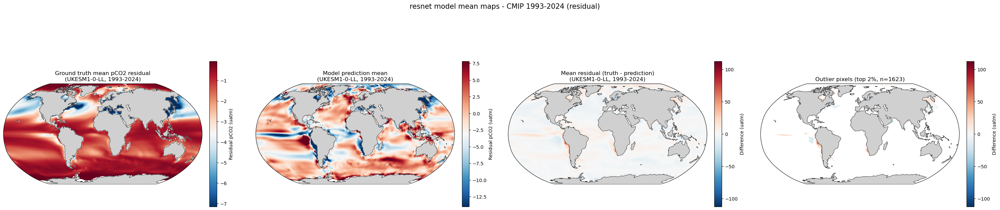

Truth mean range: -26.537 to -0.002 uatm
Prediction mean range: -116.946 to 88.967 uatm
Mean absolute difference: 3.464 uatm


In [39]:
plot_mean_comparison_maps(
    test_full_true_resid, test_full_land_mask,
    f"Ground truth mean pCO2 residual\n({TEST_MODEL}, 1993-2024)",
    test_full_pred_resid, test_full_land_mask,
    f"Model prediction mean\n({TEST_MODEL}, 1993-2024)",
    lats, lons,
    "resnet model mean maps - CMIP 1993-2024 (residual)",
    "resnet_pCO2_resid_cmip_mean_map_1970_2024.png",
    diff_title=f"Mean residual (truth - prediction)\n({TEST_MODEL}, 1993-2024)",
    diff_order="a_minus_b",
    cbar_mode="Residual",
    label_a="Truth", label_b="Prediction",
    mode="annual"
)

#### CMIP6 truth vs prediction (total pCO2)

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Truth (resnet model mean maps - CMIP 1993-2024 (total pCO2))] top 2% outliers (|value| >= 452.78), n=826
  lat= -36.50 lon= -73.50 value=  695.02
  lat= -35.50 lon= -73.50 value=  682.73
  lat= -35.50 lon= -74.50 value=  678.82
  lat= -37.50 lon= -73.50 value=  677.70
  lat= -34.50 lon= -74.50 value=  670.76
  lat= -34.50 lon= -73.50 value=  661.88
  lat= -36.50 lon= -74.50 value=  658.42
  lat= -33.50 lon= -74.50 value=  654.45
  lat= -33.50 lon= -73.50 value=  649.87
  lat= -32.50 lon= -74.50 value=  642.52
  lat= -34.50 lon= -72.50 value=  642.42
  lat= -38.50 lon= -73.50 value=  640.45
  lat= -31.50 lon= -74.50 value=  637.04
  lat= -32.50 lon= -73.50 value=  629.38
  lat= -33.50 lon= -72.50 value=  627.52

[Prediction (resnet model mean maps - CMIP 1993-2024 (total pCO2))] top 2% outliers (|value| >= 449.75), n=826
  lat= -36.50 lon= -73.50 value=  663.55
  lat= -35.50 lon= -73.50 value=  658.48
  lat= -34.50 lon= -74.50 value=  655.15
  lat= -35.50 lon= -74.50 value=  653.96
  

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_cmip_mean_map_1993_2024.png


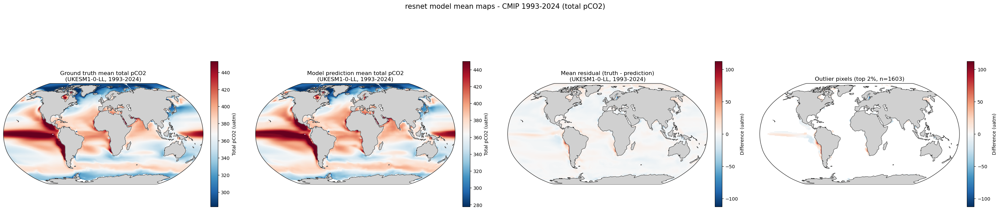

Truth mean range: 216.258 to 695.024 uatm
Prediction mean range: 205.072 to 663.547 uatm
Mean absolute difference: 3.464 uatm


In [40]:
plot_mean_comparison_maps(
    test_full_true_total, test_full_land_mask,
    f"Ground truth mean total pCO2\n({TEST_MODEL}, 1993-2024)",
    test_full_pred_total, test_full_land_mask,
    f"Model prediction mean total pCO2\n({TEST_MODEL}, 1993-2024)",
    lats, lons,
    "resnet model mean maps - CMIP 1993-2024 (total pCO2)",
    "resnet_pCO2_total_cmip_mean_map_1993_2024.png",
    diff_title=f"Mean residual (truth - prediction)\n({TEST_MODEL}, 1993-2024)",
    diff_order="a_minus_b",
    cbar_mode="Total",
    label_a="Truth", label_b="Prediction",
    mode="annual"
)

#### Satellite vs CMIP6 predictions (residual pCO2)

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Satellite (resnet model mean maps - satellite vs CMIP (residual pCO2))] top 2% outliers (|value| >= 49.52), n=786
  lat=  73.50 lon= 120.50 value= -156.38
  lat=  65.50 lon=  24.50 value= -153.10
  lat=  72.50 lon= 131.50 value= -151.43
  lat=  72.50 lon= 132.50 value= -150.71
  lat=  71.50 lon= 131.50 value= -150.69
  lat=  58.50 lon=  18.50 value= -150.27
  lat=  57.50 lon=  17.50 value= -148.58
  lat=  73.50 lon= 131.50 value= -145.61
  lat=  56.50 lon=  18.50 value= -144.78
  lat=  65.50 lon=  35.50 value= -143.87
  lat=  73.50 lon= 132.50 value= -141.71
  lat=  64.50 lon=  23.50 value= -141.31
  lat=  73.50 lon=  80.50 value= -141.14
  lat=  72.50 lon= 133.50 value= -139.74
  lat= -22.50 lon=  13.50 value=  139.02

[CMIP (resnet model mean maps - satellite vs CMIP (residual pCO2))] top 2% outliers (|value| >= 15.06), n=826
  lat= -29.50 lon= -71.50 value= -116.95
  lat= -28.50 lon= -71.50 value=  -92.00
  lat= -14.50 lon= -76.50 value=  -89.09
  lat=  59.50 lon=  23.50 value=   

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_resid_sat_vs_cmip_mean_map_1993_2024.png


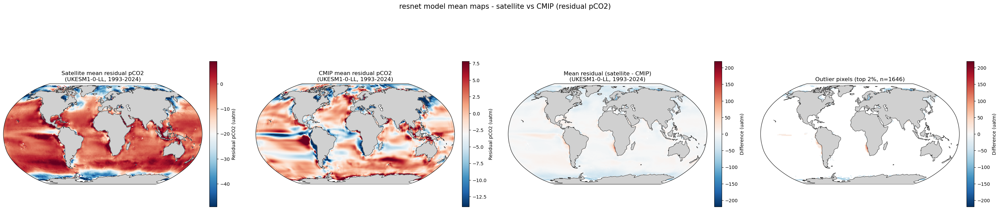

Satellite mean range: -156.382 to 139.024 uatm
CMIP mean range: -116.946 to 88.967 uatm
Mean absolute difference: 10.292 uatm


In [41]:
if USE_SATELLITE:
    plot_mean_comparison_maps(
        sat_full_pred_resid, sat_full_invalid_mask,
        f"Satellite mean residual pCO2\n({TEST_MODEL}, 1993-2024)",
        test_full_pred_resid, test_full_land_mask,
        f"CMIP mean residual pCO2\n({TEST_MODEL}, 1993-2024)",
        sat_lats, sat_lons,
        "resnet model mean maps - satellite vs CMIP (residual pCO2)",
        "resnet_pCO2_resid_sat_vs_cmip_mean_map_1993_2024.png",
        diff_title=f"Mean residual (satellite - CMIP)\n({TEST_MODEL}, 1993-2024)",
        diff_order="a_minus_b",
        cbar_mode="Residual",
        label_a="Satellite", label_b="CMIP",
        mode="annual",
    )

#### Satellite vs CMIP6 predictions (total pCO2)

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[Satellite (resnet model mean maps - satellite vs CMIP (total pCO2))] top 2% outliers (|value| >= 48.43), n=786
  lat=  73.50 lon= 120.50 value= -154.71
  lat=  58.50 lon=  18.50 value= -150.10
  lat=  71.50 lon= 131.50 value= -149.75
  lat=  72.50 lon= 132.50 value= -149.19
  lat=  72.50 lon= 131.50 value= -149.06
  lat=  57.50 lon=  17.50 value= -148.24
  lat=  65.50 lon=  24.50 value= -147.20
  lat=  56.50 lon=  18.50 value= -144.66
  lat=  65.50 lon=  35.50 value= -143.49
  lat=  73.50 lon= 131.50 value= -142.77
  lat=  64.50 lon=  23.50 value= -140.01
  lat=  73.50 lon= 132.50 value= -139.69
  lat=  73.50 lon=  80.50 value= -139.60
  lat= -22.50 lon=  13.50 value=  139.09
  lat=  80.50 lon= -81.50 value= -138.27

[CMIP (resnet model mean maps - satellite vs CMIP (total pCO2))] top 2% outliers (|value| >= 444.73), n=826
  lat= -36.50 lon= -73.50 value=  660.66
  lat= -35.50 lon= -73.50 value=  649.17
  lat= -35.50 lon= -74.50 value=  645.62
  lat= -33.50 lon= -73.50 value=  645.36

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_sat_vs_cmip_mean_map_1993_2024.png


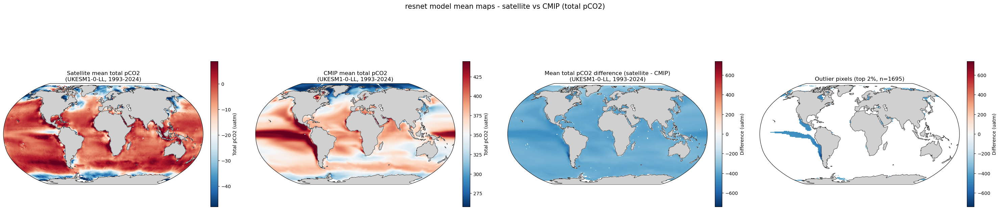

Satellite mean range: -154.712 to 139.086 uatm
CMIP mean range: 196.126 to 660.657 uatm
Mean absolute difference: 370.995 uatm


In [42]:
if USE_SATELLITE:
    plot_mean_comparison_maps(
        sat_full_pred_total.values, sat_full_invalid_mask,
        f"Satellite mean total pCO2\n({TEST_MODEL}, 1993-2024)",
        test_recon_pred_total, test_recon_land_mask,
        f"CMIP mean total pCO2\n({TEST_MODEL}, 1993-2024)",
        sat_lats, sat_lons,
        "resnet model mean maps - satellite vs CMIP (total pCO2)",
        "resnet_pCO2_total_sat_vs_cmip_mean_map_1993_2024.png",
        diff_title=f"Mean total pCO2 difference (satellite - CMIP)\n({TEST_MODEL}, 1993-2024)",
        diff_order="a_minus_b",
        cbar_mode="Total",
        label_a="Satellite", label_b="CMIP",
        mode="annual",
    )

diagnostic - rmv

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CNN residual (Component breakdown - satellite total pCO2)] top 2% outliers (|value| >= 49.52), n=786
  lat=  73.50 lon= 120.50 value= -156.38
  lat=  65.50 lon=  24.50 value= -153.10
  lat=  72.50 lon= 131.50 value= -151.43
  lat=  72.50 lon= 132.50 value= -150.71
  lat=  71.50 lon= 131.50 value= -150.69
  lat=  58.50 lon=  18.50 value= -150.27
  lat=  57.50 lon=  17.50 value= -148.58
  lat=  73.50 lon= 131.50 value= -145.61
  lat=  56.50 lon=  18.50 value= -144.78
  lat=  65.50 lon=  35.50 value= -143.87
  lat=  73.50 lon= 132.50 value= -141.71
  lat=  64.50 lon=  23.50 value= -141.31
  lat=  73.50 lon=  80.50 value= -141.14
  lat=  72.50 lon= 133.50 value= -139.74
  lat= -22.50 lon=  13.50 value=  139.02

[Thermal term (Component breakdown - satellite total pCO2)] top 2% outliers (|value| >= 2.67), n=786
  lat=  22.50 lon= -82.50 value=   19.41
  lat= -32.50 lon= 115.50 value=   10.31
  lat=  75.50 lon= 162.50 value=    9.72
  lat=  74.50 lon= 163.50 value=    8.66
  lat=  74.50 lo

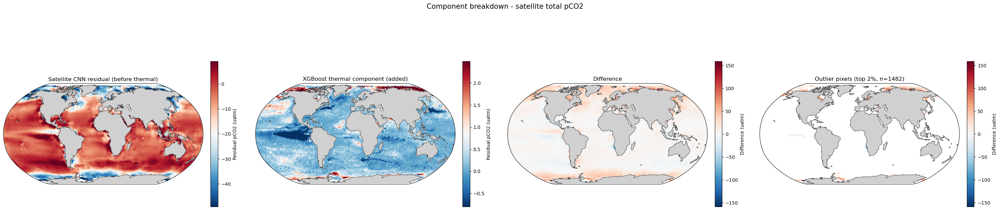

CNN residual mean range: -156.382 to 139.024 uatm
Thermal term mean range: -6.622 to 19.407 uatm
Mean absolute difference: 11.203 uatm


In [43]:
plot_mean_comparison_maps(
    sat_full_pred_resid, sat_full_invalid_mask,
    "Satellite CNN residual (before thermal)",
    pco2_thermal_full.values, sat_full_invalid_mask,
    "XGBoost thermal component (added)",
    sat_lats, sat_lons,
    "Component breakdown - satellite total pCO2",
    save_name=None,
    cbar_mode="Residual",
    label_a="CNN residual", label_b="Thermal term",
    mode="annual",
)

### 2. Seasonal mean maps (WI, SP, SU, FA)

In [44]:
seasons = ["DJF", "MAM", "JJA", "SON"]

#### CMIP6 truth vs prediction (residual pCO2)


[Truth (resnet model seasonal mean maps - DJF (1993-2024, residual))] top 2% outliers (|value| >= 67.30), n=826
  lat=  69.50 lon= -81.50 value=  167.60
  lat=  56.50 lon= 143.50 value=  164.94
  lat=  57.50 lon= 144.50 value=  164.08
  lat=  57.50 lon= 143.50 value=  158.84
  lat=  56.50 lon= 144.50 value=  158.21
  lat=  56.50 lon= 142.50 value=  157.09
  lat=  57.50 lon= 145.50 value=  154.98
  lat=  55.50 lon= 143.50 value=  153.78
  lat=  55.50 lon= 144.50 value=  153.20
  lat=  69.50 lon= -80.50 value=  151.36
  lat=  72.50 lon= 137.50 value=  148.01
  lat=  56.50 lon= 141.50 value=  144.72
  lat=  72.50 lon= 136.50 value=  144.34
  lat=  56.50 lon= 145.50 value=  143.89
  lat=  69.50 lon= -79.50 value=  143.23

[Prediction (resnet model seasonal mean maps - DJF (1993-2024, residual))] top 2% outliers (|value| >= 58.72), n=826
  lat=  59.50 lon=  23.50 value=  244.89
  lat=  59.50 lon=  22.50 value=  225.15
  lat=  58.50 lon=  22.50 value=  206.79
  lat= -29.50 lon= -71.50 value

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_DJF_1993_2024.png


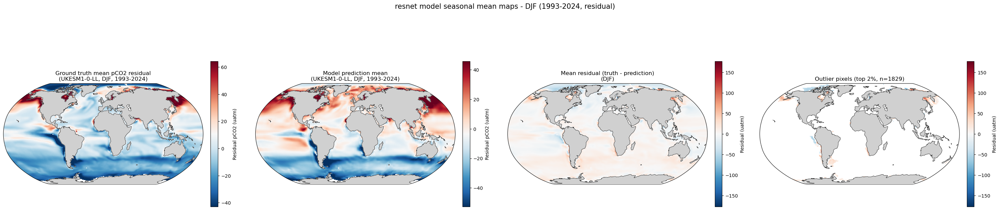

Truth mean range: -139.238 to 167.600 uatm
Prediction mean range: -185.707 to 244.893 uatm
Mean absolute difference: 10.233 uatm

[Truth (resnet model seasonal mean maps - MAM (1993-2024, residual))] top 2% outliers (|value| >= 64.30), n=826
  lat=  61.50 lon= -92.50 value=  262.45
  lat=  60.50 lon= -91.50 value=  249.69
  lat=  60.50 lon= -92.50 value=  248.50
  lat=  61.50 lon= -91.50 value=  241.71
  lat=  60.50 lon= -90.50 value=  228.92
  lat=  62.50 lon= -91.50 value=  223.94
  lat=  60.50 lon= -93.50 value=  221.98
  lat=  63.50 lon= -89.50 value=  210.77
  lat=  62.50 lon= -90.50 value=  209.05
  lat=  61.50 lon= -90.50 value=  203.25
  lat=  60.50 lon= -89.50 value=  200.02
  lat=  62.50 lon= -92.50 value=  198.98
  lat=  59.50 lon= -90.50 value=  197.51
  lat=  59.50 lon= -91.50 value=  194.39
  lat=  59.50 lon= -89.50 value=  193.99

[Prediction (resnet model seasonal mean maps - MAM (1993-2024, residual))] top 2% outliers (|value| >= 45.58), n=826
  lat=  59.50 lon=  22.50

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_MAM_1993_2024.png


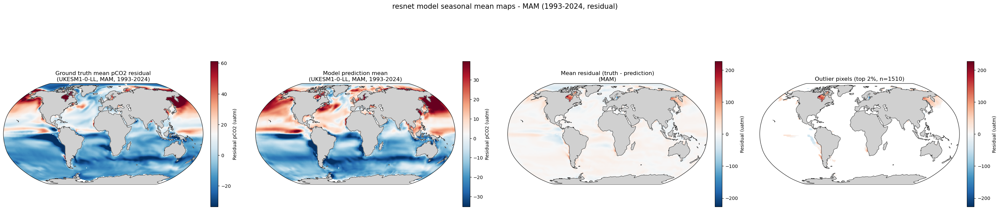

Truth mean range: -112.191 to 262.454 uatm
Prediction mean range: -176.300 to 220.027 uatm
Mean absolute difference: 8.624 uatm

[Truth (resnet model seasonal mean maps - JJA (1993-2024, residual))] top 2% outliers (|value| >= 84.87), n=826
  lat= -38.50 lon= -73.50 value=  212.84
  lat= -37.50 lon= -73.50 value=  192.92
  lat=  69.50 lon= -81.50 value= -186.14
  lat= -39.50 lon= -74.50 value=  183.89
  lat=  69.50 lon= -80.50 value= -177.88
  lat=  68.50 lon= -80.50 value= -177.43
  lat=  67.50 lon= -80.50 value= -176.86
  lat=  69.50 lon= -79.50 value= -176.12
  lat=  62.50 lon= -92.50 value= -173.02
  lat=  69.50 lon= -78.50 value= -172.81
  lat= -40.50 lon= -74.50 value=  171.65
  lat=  69.50 lon= -77.50 value= -170.96
  lat=  61.50 lon= -92.50 value= -169.51
  lat=  62.50 lon= -91.50 value= -168.13
  lat=  68.50 lon= -77.50 value= -166.09

[Prediction (resnet model seasonal mean maps - JJA (1993-2024, residual))] top 2% outliers (|value| >= 76.20), n=826
  lat=  74.50 lon= 112.50 

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_JJA_1993_2024.png


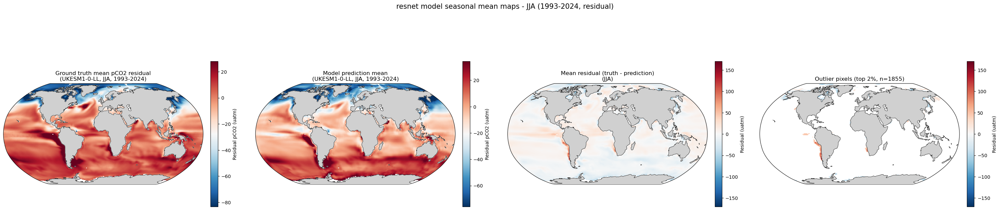

Truth mean range: -186.137 to 212.840 uatm
Prediction mean range: -131.902 to 98.405 uatm
Mean absolute difference: 9.112 uatm

[Truth (resnet model seasonal mean maps - SON (1993-2024, residual))] top 2% outliers (|value| >= 70.09), n=826
  lat=  63.50 lon= -89.50 value= -153.02
  lat=  62.50 lon= -91.50 value= -149.82
  lat=  60.50 lon= -91.50 value= -144.33
  lat=  62.50 lon= -92.50 value= -144.32
  lat=  60.50 lon= -92.50 value= -143.38
  lat=  62.50 lon= -90.50 value= -141.62
  lat=  60.50 lon= -90.50 value= -139.18
  lat=  61.50 lon= -92.50 value= -135.95
  lat=  63.50 lon= -88.50 value= -135.01
  lat=  61.50 lon= -91.50 value= -134.75
  lat=  59.50 lon= -89.50 value= -134.50
  lat=  59.50 lon= -90.50 value= -133.66
  lat=  59.50 lon= -91.50 value= -132.46
  lat=  60.50 lon= -89.50 value= -131.54
  lat=  59.50 lon= -88.50 value= -131.27

[Prediction (resnet model seasonal mean maps - SON (1993-2024, residual))] top 2% outliers (|value| >= 46.20), n=826
  lat= -72.50 lon= -74.50 v

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_SON_1993_2024.png


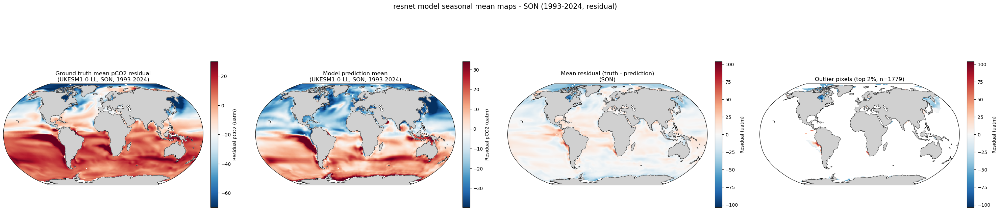

Truth mean range: -153.021 to 98.460 uatm
Prediction mean range: -122.077 to 124.406 uatm
Mean absolute difference: 10.644 uatm


In [45]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_true_resid, test_recon_land_mask,
        f"Ground truth mean pCO2 residual\n({TEST_MODEL}, {season}, 1993-2024)",
        test_recon_pred_resid, test_recon_land_mask,
        f"Model prediction mean\n({TEST_MODEL}, {season}, 1993-2024)",
        lats, lons,
        f"resnet model seasonal mean maps - {season} (1993-2024, residual)",
        f"resnet_pCO2_res_cmip_{season}_1993_2024.png",
        diff_title=f"Mean residual (truth - prediction)\n({season})",
        diff_order="a_minus_b",
        diff_cbar_label="Residual (uatm)",
        label_a="Truth", label_b="Prediction",
        time_a=test_recon_time, time_b=test_recon_time,
        mode="season", season=season,
    )

#### CMIP6 truth vs prediction (total pCO2)


[Truth (resnet model seasonal mean maps - DJF (1993-2024, total pCO2))] top 2% outliers (|value| >= 452.25), n=826
  lat= -35.50 lon= -73.50 value=  719.61
  lat= -35.50 lon= -74.50 value=  715.16
  lat= -36.50 lon= -73.50 value=  713.25
  lat= -34.50 lon= -74.50 value=  697.24
  lat= -34.50 lon= -72.50 value=  696.60
  lat= -34.50 lon= -73.50 value=  691.98
  lat= -33.50 lon= -72.50 value=  678.82
  lat= -36.50 lon= -74.50 value=  675.82
  lat= -33.50 lon= -73.50 value=  667.44
  lat= -33.50 lon= -74.50 value=  665.27
  lat= -32.50 lon= -72.50 value=  660.02
  lat= -37.50 lon= -73.50 value=  653.96
  lat= -32.50 lon= -74.50 value=  640.08
  lat= -31.50 lon= -72.50 value=  638.39
  lat= -32.50 lon= -73.50 value=  636.28

[Prediction (resnet model seasonal mean maps - DJF (1993-2024, total pCO2))] top 2% outliers (|value| >= 446.50), n=826
  lat= -33.50 lon= -73.50 value=  668.99
  lat= -31.50 lon= -74.50 value=  666.99
  lat= -30.50 lon= -74.50 value=  660.12
  lat= -32.50 lon= -73.50

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_cmip_DJF_1993_2024.png


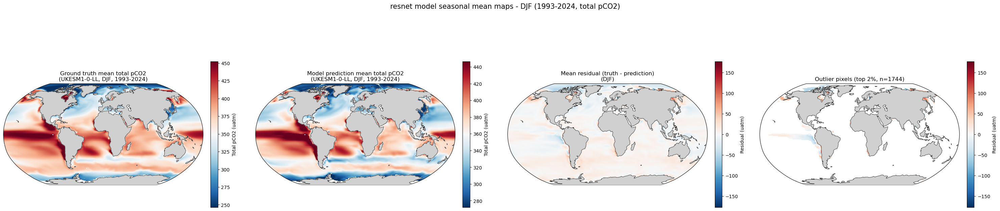

Truth mean range: 163.887 to 719.606 uatm
Prediction mean range: 203.944 to 668.993 uatm
Mean absolute difference: 10.233 uatm

[Truth (resnet model seasonal mean maps - MAM (1993-2024, total pCO2))] top 2% outliers (|value| >= 458.19), n=826
  lat= -37.50 lon= -73.50 value=  777.85
  lat= -36.50 lon= -73.50 value=  768.13
  lat= -35.50 lon= -74.50 value=  757.15
  lat= -38.50 lon= -73.50 value=  747.85
  lat= -36.50 lon= -74.50 value=  743.05
  lat= -34.50 lon= -74.50 value=  741.40
  lat= -35.50 lon= -73.50 value=  722.14
  lat=  61.50 lon= -92.50 value=  713.65
  lat= -37.50 lon= -74.50 value=  709.62
  lat= -33.50 lon= -74.50 value=  701.27
  lat= -34.50 lon= -73.50 value=  693.52
  lat=  62.50 lon= -91.50 value=  674.64
  lat= -38.50 lon= -74.50 value=  671.03
  lat=  61.50 lon= -91.50 value=  668.20
  lat= -33.50 lon= -73.50 value=  666.94

[Prediction (resnet model seasonal mean maps - MAM (1993-2024, total pCO2))] top 2% outliers (|value| >= 456.77), n=826
  lat= -36.50 lon= -7

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_cmip_MAM_1993_2024.png


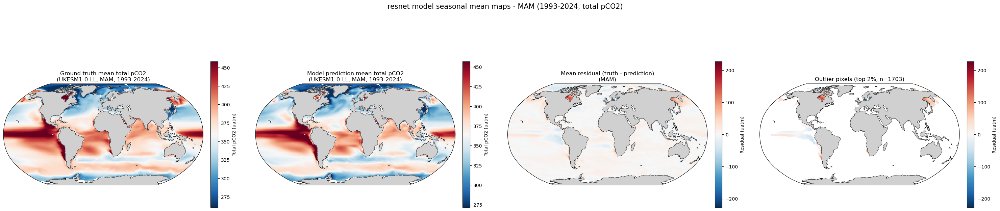

Truth mean range: 206.802 to 777.854 uatm
Prediction mean range: 213.918 to 666.500 uatm
Mean absolute difference: 8.624 uatm

[Truth (resnet model seasonal mean maps - JJA (1993-2024, total pCO2))] top 2% outliers (|value| >= 456.91), n=826
  lat= -37.50 lon= -73.50 value=  819.45
  lat= -36.50 lon= -73.50 value=  802.09
  lat= -38.50 lon= -73.50 value=  797.87
  lat= -35.50 lon= -73.50 value=  756.76
  lat= -36.50 lon= -74.50 value=  755.76
  lat= -35.50 lon= -74.50 value=  753.86
  lat= -34.50 lon= -74.50 value=  737.86
  lat= -37.50 lon= -74.50 value=  730.62
  lat= -34.50 lon= -73.50 value=  727.56
  lat= -33.50 lon= -74.50 value=  713.69
  lat= -33.50 lon= -73.50 value=  707.49
  lat= -32.50 lon= -74.50 value=  699.98
  lat= -39.50 lon= -74.50 value=  698.70
  lat= -31.50 lon= -74.50 value=  688.69
  lat= -38.50 lon= -74.50 value=  680.84

[Prediction (resnet model seasonal mean maps - JJA (1993-2024, total pCO2))] top 2% outliers (|value| >= 444.38), n=826
  lat= -36.50 lon= -73

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_cmip_JJA_1993_2024.png


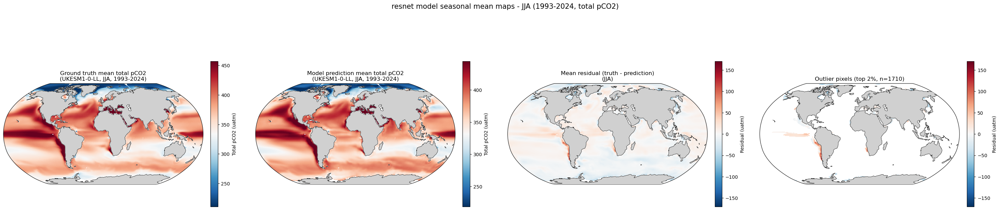

Truth mean range: 147.035 to 819.452 uatm
Prediction mean range: 139.045 to 694.618 uatm
Mean absolute difference: 9.112 uatm

[Truth (resnet model seasonal mean maps - SON (1993-2024, total pCO2))] top 2% outliers (|value| >= 450.67), n=826
  lat= -31.50 lon= -74.50 value=  654.79
  lat= -30.50 lon= -74.50 value=  649.83
  lat= -32.50 lon= -74.50 value=  645.79
  lat= -32.50 lon= -73.50 value=  636.52
  lat= -33.50 lon= -74.50 value=  636.32
  lat= -31.50 lon= -73.50 value=  634.71
  lat= -33.50 lon= -73.50 value=  634.21
  lat= -35.50 lon= -73.50 value=  631.78
  lat= -34.50 lon= -74.50 value=  627.93
  lat= -36.50 lon= -73.50 value=  626.07
  lat= -34.50 lon= -73.50 value=  625.78
  lat= -35.50 lon= -74.50 value=  625.72
  lat= -23.50 lon= -70.50 value=  622.21
  lat= -22.50 lon= -70.50 value=  621.50
  lat= -30.50 lon= -73.50 value=  620.98

[Prediction (resnet model seasonal mean maps - SON (1993-2024, total pCO2))] top 2% outliers (|value| >= 446.03), n=826
  lat= -36.50 lon= -73

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_total_cmip_SON_1993_2024.png


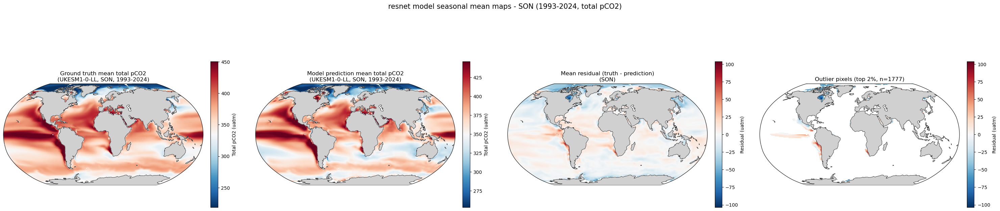

Truth mean range: 159.063 to 654.788 uatm
Prediction mean range: 179.063 to 633.078 uatm
Mean absolute difference: 10.644 uatm


In [46]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_true_total, test_recon_land_mask,
        f"Ground truth mean total pCO2\n({TEST_MODEL}, {season}, 1993-2024)",
        test_recon_pred_total, test_recon_land_mask,
        f"Model prediction mean total pCO2\n({TEST_MODEL}, {season}, 1993-2024)",
        lats, lons,
        f"resnet model seasonal mean maps - {season} (1993-2024, total pCO2)",
        f"resnet_pCO2_total_cmip_{season}_1993_2024.png",
        diff_title=f"Mean residual (truth - prediction)\n({season})",
        diff_order="a_minus_b",
        cbar_mode="Total",
        diff_cbar_label="Residual (uatm)",
        label_a="Truth", label_b="Prediction",
        time_a=test_recon_time, time_b=test_recon_time,
        mode="season", season=season,
    )

#### Satellite vs CMIP6 predictions (residual pCO2)


[CMIP (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 58.72), n=826
  lat=  59.50 lon=  23.50 value=  244.89
  lat=  59.50 lon=  22.50 value=  225.15
  lat=  58.50 lon=  22.50 value=  206.79
  lat= -29.50 lon= -71.50 value= -185.71
  lat=  59.50 lon=  21.50 value=  163.09
  lat= -28.50 lon= -71.50 value= -149.77
  lat=  55.50 lon=  20.50 value=  148.93
  lat=  58.50 lon=  21.50 value=  141.47
  lat=  60.50 lon= 160.50 value=  137.91
  lat= -27.50 lon= -71.50 value= -137.53
  lat= -14.50 lon= -76.50 value= -131.59
  lat=  57.50 lon=  20.50 value=  130.89
  lat= -26.50 lon= -71.50 value= -129.73
  lat= -19.50 lon= -70.50 value= -127.23
  lat= -25.50 lon= -71.50 value= -126.35

[Satellite (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 54.31), n=717
  lat=  56.50 lon=  20.50 value=  251.06
  lat=  55.50 lon=  20.50 value=  249.15
  lat=  41.50 lon=  31.50 value=  188.34
  lat=  54.50 lon=  19.50 value=  177.56
  lat=  57.50 lon=  20.50 

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_DJF_1993_2024.png


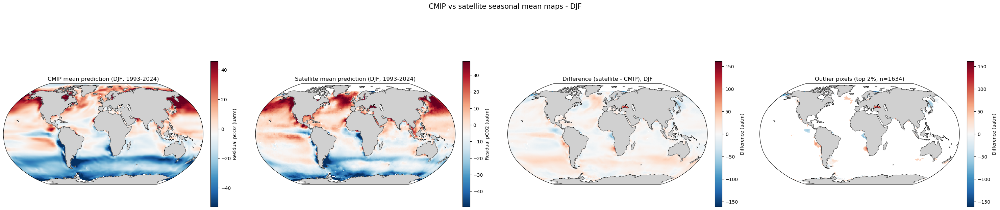

CMIP mean range: -185.707 to 244.893 uatm
Satellite mean range: -142.258 to 251.059 uatm
Mean absolute difference: 9.606 uatm

[CMIP (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 45.58), n=826
  lat=  59.50 lon=  22.50 value=  220.03
  lat=  58.50 lon=  21.50 value=  206.49
  lat=  59.50 lon=  21.50 value=  202.28
  lat=  59.50 lon=  23.50 value=  201.52
  lat=  58.50 lon=  22.50 value=  197.84
  lat= -29.50 lon= -71.50 value= -176.30
  lat=  58.50 lon=  20.50 value=  174.08
  lat=  57.50 lon=  20.50 value=  173.53
  lat=  55.50 lon=  20.50 value=  153.31
  lat= -26.50 lon=  14.50 value= -146.16
  lat= -25.50 lon=  14.50 value= -144.63
  lat= -28.50 lon= -71.50 value= -143.81
  lat=  59.50 lon=  20.50 value=  142.20
  lat= -24.50 lon=  14.50 value= -132.11
  lat= -27.50 lon= -71.50 value= -129.04

[Satellite (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 44.34), n=753
  lat=   0.50 lon= -49.50 value= -191.60
  lat=  57.50 lon=  20.

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_MAM_1993_2024.png


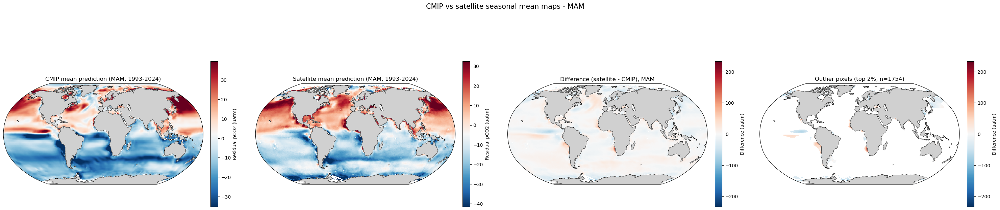

CMIP mean range: -176.300 to 220.027 uatm
Satellite mean range: -191.596 to 150.255 uatm
Mean absolute difference: 9.097 uatm

[CMIP (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 76.20), n=826
  lat=  74.50 lon= 112.50 value= -131.90
  lat=  68.50 lon=-101.50 value= -122.49
  lat=  73.50 lon= 120.50 value= -122.07
  lat=  60.50 lon=  19.50 value= -121.11
  lat=  54.50 lon= -80.50 value= -120.89
  lat=  68.50 lon=-100.50 value= -120.07
  lat=  64.50 lon=-177.50 value= -119.52
  lat=  69.50 lon=-101.50 value= -115.49
  lat=  63.50 lon=-177.50 value= -114.14
  lat=  64.50 lon=-175.50 value= -114.06
  lat=  74.50 lon= -84.50 value= -113.69
  lat=  64.50 lon=-176.50 value= -113.41
  lat=  59.50 lon=  19.50 value= -112.89
  lat=  63.50 lon= -89.50 value= -112.85
  lat=  59.50 lon= 157.50 value= -111.98

[Satellite (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 78.31), n=724
  lat=  56.50 lon=  18.50 value= -377.58
  lat=  56.50 lon=  19.

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_JJA_1993_2024.png


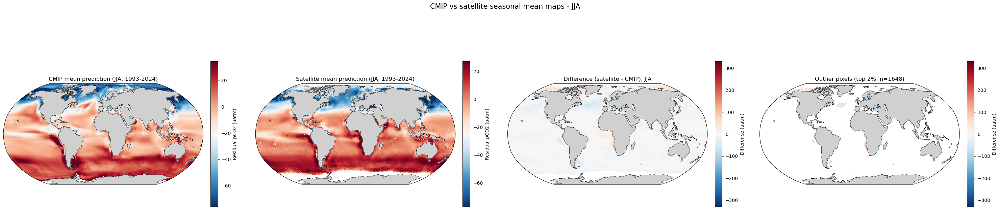

CMIP mean range: -131.902 to 98.405 uatm
Satellite mean range: -377.579 to 187.489 uatm
Mean absolute difference: 9.926 uatm

[CMIP (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 46.20), n=826
  lat= -72.50 lon= -74.50 value=  124.41
  lat=  60.50 lon=  19.50 value= -122.08
  lat=  33.50 lon= 121.50 value= -118.03
  lat=  60.50 lon=  20.50 value= -108.65
  lat=  33.50 lon= 122.50 value= -107.08
  lat=  34.50 lon= 121.50 value= -104.84
  lat= -72.50 lon= -75.50 value=  104.69
  lat=  38.50 lon= 121.50 value= -102.96
  lat= -35.50 lon= -56.50 value=  102.59
  lat=  59.50 lon=  19.50 value=  -95.60
  lat=  38.50 lon= 122.50 value=  -92.35
  lat=  20.50 lon=  88.50 value=  -90.84
  lat= -36.50 lon= -56.50 value=   88.30
  lat=  32.50 lon= 122.50 value=  -87.79
  lat=  38.50 lon= 120.50 value=  -87.63

[Satellite (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 67.00), n=773
  lat= -19.50 lon=  12.50 value=  223.43
  lat= -21.50 lon=  13.5

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)


Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_SON_1993_2024.png


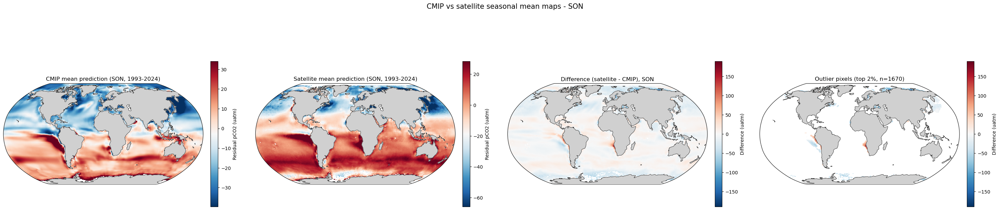

CMIP mean range: -122.077 to 124.406 uatm
Satellite mean range: -197.687 to 223.432 uatm
Mean absolute difference: 10.365 uatm


In [47]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_pred_resid, test_recon_land_mask,
        f"CMIP mean prediction ({season}, 1993-2024)",
        sat_full_pred_resid, sat_full_invalid_mask,
        f"Satellite mean prediction ({season}, 1993-2024)",
        lats, lons,
        f"CMIP vs satellite seasonal mean maps - {season}",
        f"resnet_pCO2_res_cmip_vs_satellite_{season}_1993_2024.png",
        diff_title=f"Difference (satellite - CMIP), {season}",
        diff_order="b_minus_a",
        label_a="CMIP", label_b="Satellite",
        time_a=test_recon_time, time_b=sat_full_time,
        mode="season", season=season,
    )

#### Satellite vs CMIP6 predictions (total pCO2)

/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 446.50), n=826
  lat= -33.50 lon= -73.50 value=  668.99
  lat= -31.50 lon= -74.50 value=  666.99
  lat= -30.50 lon= -74.50 value=  660.12
  lat= -32.50 lon= -73.50 value=  658.24
  lat= -32.50 lon= -74.50 value=  657.38
  lat= -35.50 lon= -73.50 value=  653.94
  lat= -33.50 lon= -74.50 value=  653.30
  lat= -31.50 lon= -73.50 value=  651.41
  lat= -34.50 lon= -74.50 value=  650.21
  lat= -35.50 lon= -74.50 value=  650.14
  lat= -34.50 lon= -73.50 value=  649.21
  lat= -36.50 lon= -73.50 value=  648.43
  lat= -33.50 lon= -72.50 value=  647.87
  lat= -32.50 lon= -72.50 value=  643.48
  lat= -34.50 lon= -72.50 value=  643.42

[Satellite (CMIP vs satellite seasonal mean maps - DJF)] top 2% outliers (|value| >= 53.99), n=717
  lat=  56.50 lon=  20.50 value=  252.08
  lat=  55.50 lon=  20.50 value=  248.66
  lat=  41.50 lon=  31.50 value=  190.24
  lat=  54.50 lon=  19.50 value=  178.51
  lat=  57.50 lon=  20.50

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_DJF_1993_2024.png


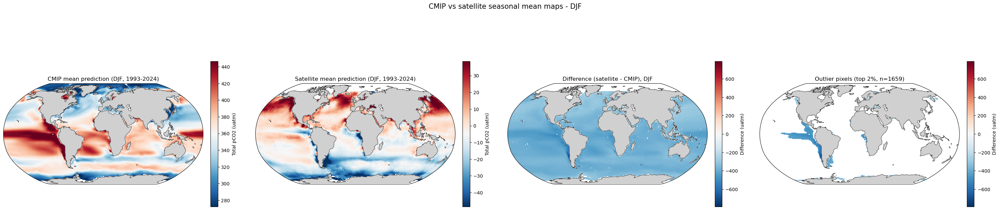

CMIP mean range: 203.944 to 668.993 uatm
Satellite mean range: -142.258 to 252.076 uatm
Mean absolute difference: 369.510 uatm


/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 456.77), n=826
  lat= -36.50 lon= -73.50 value=  666.50
  lat= -35.50 lon= -73.50 value=  655.20
  lat= -37.50 lon= -73.50 value=  654.96
  lat= -33.50 lon= -73.50 value=  652.57
  lat= -35.50 lon= -74.50 value=  652.21
  lat= -34.50 lon= -74.50 value=  649.17
  lat= -33.50 lon= -74.50 value=  644.79
  lat= -34.50 lon= -73.50 value=  639.94
  lat= -36.50 lon= -74.50 value=  637.44
  lat= -32.50 lon= -74.50 value=  631.92
  lat= -33.50 lon= -72.50 value=  626.70
  lat= -34.50 lon= -72.50 value=  623.65
  lat= -31.50 lon= -74.50 value=  619.70
  lat= -38.50 lon= -73.50 value=  619.11
  lat= -32.50 lon= -73.50 value=  617.89

[Satellite (CMIP vs satellite seasonal mean maps - MAM)] top 2% outliers (|value| >= 43.93), n=753
  lat=   0.50 lon= -49.50 value= -189.63
  lat=  57.50 lon=  20.50 value=  150.26
  lat=   1.50 lon= -48.50 value= -147.23
  lat=  58.50 lon=  20.50 value=  142.88
  lat=  -0.50 lon= -47.50

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_MAM_1993_2024.png


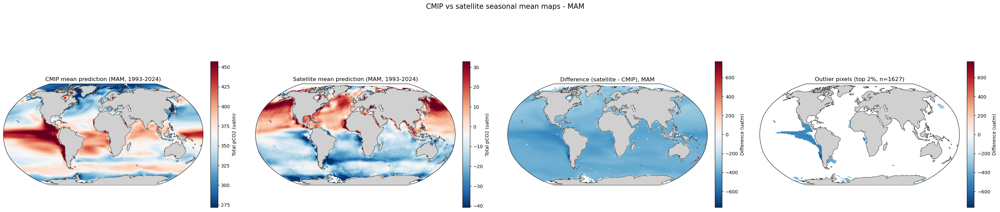

CMIP mean range: 213.918 to 666.500 uatm
Satellite mean range: -189.629 to 150.255 uatm
Mean absolute difference: 370.496 uatm


/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 444.38), n=826
  lat= -36.50 lon= -73.50 value=  694.62
  lat= -37.50 lon= -73.50 value=  681.30
  lat= -35.50 lon= -73.50 value=  664.18
  lat= -35.50 lon= -74.50 value=  647.60
  lat= -36.50 lon= -74.50 value=  644.06
  lat= -34.50 lon= -73.50 value=  642.15
  lat= -34.50 lon= -74.50 value=  640.83
  lat= -33.50 lon= -74.50 value=  630.86
  lat= -38.50 lon= -73.50 value=  627.73
  lat= -33.50 lon= -73.50 value=  627.52
  lat= -34.50 lon= -72.50 value=  621.24
  lat= -37.50 lon= -74.50 value=  614.31
  lat= -32.50 lon= -74.50 value=  610.10
  lat= -30.50 lon= -74.50 value=  603.70
  lat= -31.50 lon= -74.50 value=  600.97

[Satellite (CMIP vs satellite seasonal mean maps - JJA)] top 2% outliers (|value| >= 77.66), n=724
  lat=  56.50 lon=  18.50 value= -377.58
  lat=  56.50 lon=  19.50 value= -360.26
  lat=  57.50 lon=  19.50 value= -340.39
  lat=  59.50 lon=  23.50 value= -333.56
  lat=  58.50 lon=  18.50

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_JJA_1993_2024.png


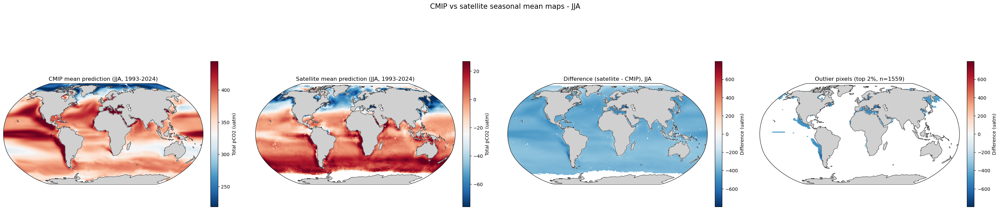

CMIP mean range: 139.045 to 694.618 uatm
Satellite mean range: -377.579 to 187.489 uatm
Mean absolute difference: 371.599 uatm


/var/tmp/pbs.3894937.pbs-7/ipykernel_2567455/1061470387.py:92: RuntimeWarning: Mean of empty slice
  return np.nanmean(masked, axis=0)



[CMIP (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 446.03), n=826
  lat= -36.50 lon= -73.50 value=  633.08
  lat= -35.50 lon= -74.50 value=  632.52
  lat= -34.50 lon= -74.50 value=  632.46
  lat= -33.50 lon= -73.50 value=  632.35
  lat= -33.50 lon= -74.50 value=  627.14
  lat= -34.50 lon= -73.50 value=  626.15
  lat= -32.50 lon= -74.50 value=  625.47
  lat= -31.50 lon= -74.50 value=  624.97
  lat= -30.50 lon= -74.50 value=  624.78
  lat= -35.50 lon= -73.50 value=  623.34
  lat= -36.50 lon= -74.50 value=  615.93
  lat= -32.50 lon= -73.50 value=  614.95
  lat= -37.50 lon= -73.50 value=  613.36
  lat= -29.50 lon= -74.50 value=  606.76
  lat= -29.50 lon= -73.50 value=  596.68

[Satellite (CMIP vs satellite seasonal mean maps - SON)] top 2% outliers (|value| >= 66.42), n=773
  lat= -19.50 lon=  12.50 value=  224.97
  lat= -21.50 lon=  13.50 value=  209.69
  lat= -19.50 lon=  11.50 value=  206.03
  lat= -20.50 lon=  12.50 value=  199.04
  lat=  60.50 lon=  19.50

Saved mean map to: /rds/general/user/efs25/home/irp-efs25/figures/resnet_pCO2_res_cmip_vs_satellite_SON_1993_2024.png


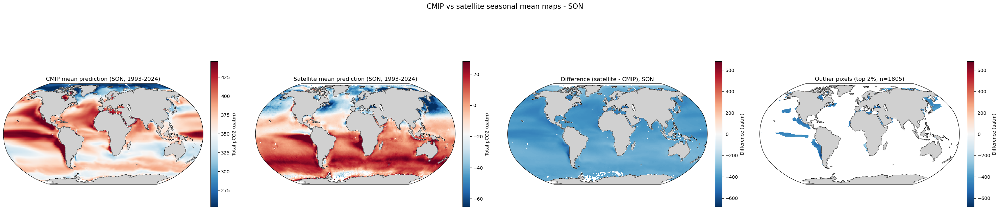

CMIP mean range: 179.063 to 633.078 uatm
Satellite mean range: -197.571 to 224.968 uatm
Mean absolute difference: 370.641 uatm


In [48]:
for season in seasons:
    plot_mean_comparison_maps(
        test_recon_pred_total, test_recon_land_mask,
        f"CMIP mean prediction ({season}, 1993-2024)",
        sat_full_pred_total.values, sat_full_invalid_mask,
        f"Satellite mean prediction ({season}, 1993-2024)",
        lats, lons,
        f"CMIP vs satellite seasonal mean maps - {season}",
        f"resnet_pCO2_res_cmip_vs_satellite_{season}_1993_2024.png",
        diff_title=f"Difference (satellite - CMIP), {season}",
        diff_order="b_minus_a",
        cbar_mode="Total",
        label_a="CMIP", label_b="Satellite",
        time_a=test_recon_time, time_b=sat_full_time,
        mode="season", season=season,
    )